# ILMT faint-streak detection — refined single-frame workflow

This notebook audits one FITS frame, validates the manually supplied two-edge DS9 annotation, estimates the background and empirical PSF, exports preprocessing provenance, and prepares a reproducible PyRaDoN/FRT experiment.

**Important scientific boundary:** the default FRT configuration targets the long, corner-crossing annotated trail (`FRT_USE_SHORT=False`) and uses a compact-source-suppressed residual. The expensive full-frame FRT search is disabled by default (`RUN_FRT=False`) until the operator has reviewed the inputs and available memory. This avoids accidentally repeating the earlier short-mode experiment, which returned short features near bright sources instead of the long annotated candidate.

Run top-to-bottom from a fresh kernel. Edit parameters only in the single configuration cell. The FITS data, DS9 annotation, and local `pyradon_reference` checkout must exist at the configured paths.


## Stage 1 — Imports and environment

Required packages: `numpy`, `matplotlib`, `pandas`, `astropy`, `sep`, `scipy`. The notebook prints versions for reproducibility. It does not install or silently update packages.

In [2]:
from pathlib import Path
import os
import sys
import re
import json
import gc
import time
import hashlib
import platform
import warnings
import subprocess
import inspect
import textwrap

import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import psutil
import scipy
import astropy
import sep

from IPython.display import display
from astropy.io import fits
from astropy.wcs import WCS
from astropy.convolution import Gaussian2DKernel, convolve
from astropy.visualization import (
    ZScaleInterval,
    ImageNormalize,
    AsinhStretch,
    ManualInterval,
)
from scipy.spatial import cKDTree
from scipy.optimize import least_squares
from scipy.ndimage import gaussian_filter, distance_transform_edt

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Astropy:", astropy.__version__)
print("SEP:", getattr(sep, "__version__", "version unavailable"))
print("SciPy:", scipy.__version__)


Python: 3.13.13
NumPy: 2.5.2
Pandas: 3.0.6
Astropy: 8.0.1
SEP: 1.4.1
SciPy: 1.18.1


## Stage 2 — Single-point configuration

Edit paths and scientifically justified settings **only here**. The sample frame and expected observation date are pinned deliberately to prevent accidental analysis of another frame.

In [3]:
# ============================================================
# SINGLE CONFIGURATION CELL — edit parameters only here
# ============================================================

# Project and input data
PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "ILMT_Contest_Materials" / "test_files"
FRAME_FILENAME = "20221026-0057.fits"
FRAME_PATH = DATA_DIR / FRAME_FILENAME
IMAGE_HDU_INDEX = 0
EDGE_REGION_PATH = PROJECT_ROOT / "annotation" / "ds9_edges_image.reg"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "preprocessing" / Path(FRAME_FILENAME).stem
PYRADON_ROOT = PROJECT_ROOT / "pyradon_reference"

# Immutable identity checks for this known diagnostic frame
EXPECTED_DATE_OBS = "2022-10-26"
EXPECTED_SHAPE = (4096, 4096)
EXPECTED_SHA256 = (
    "49d29e18f54b729456bd166f7037e551c"
    "c727d7a32e8cde5530a776527bd38a10"
)
REFERENCE_MEDIAN = 1.9607568979263306
REFERENCE_ROBUST_SIGMA = 40.93205510880947
FINGERPRINT_REL_TOL = 0.02

# Background estimation
BG_MESH_OPTIONS = (32, 64, 128)
BG_MESH_SIZE = 64
BG_FILTER_SIZE = 3

# Source detection and empirical PSF estimation
SOURCE_DETECT_THRESHOLD = 5.0
SOURCE_MIN_AREA = 5
PSF_AXIS_RATIO_MIN = 0.85
PSF_NEIGHBOUR_MIN_PIX = 15.0
PSF_FLUX_QUANTILES = (30, 90)
MAX_PSF_FITS = 200
PSF_CUTOUT_HALF_SIZE = 16
PSF_FIT_SIGMA_BOUNDS = (0.5, 10.0)
PSF_MIN_PEAK_TO_RMS = 5.0
PSF_MAX_REDUCED_CHI2 = 5.0
PSF_MIN_MINOR_SIGMA = 0.8
PSF_RANDOM_SEED = 42

# Compact-source suppression diagnostic / optional FRT input branch
STAR_MASK_RADIUS_FACTOR = 3.0
STAR_MASK_AXIS_RATIO_MIN = 0.75
STAR_MASK_MAX_SEMIAXIS_FACTOR = 3.0
STAR_MASK_MIN_SEMIAXIS_PIX = 6.0
MASK_OVERLAP_WARNING_FRACTION = 0.10

# Display-only settings
DISPLAY_ZSCALE = True
DISPLAY_ASINH_Q = 0.1
DISPLAY_SMOOTH_SIGMA_PIX = 2.0
DISPLAY_PERCENTILES = (1.0, 99.5)
RESIDUAL_DISPLAY_RMS_MULTIPLIER = 4.0
ANNOTATION_CROP_HALF_SIZE = 160
LOCAL_CONTROL_HALF_WIDTH_PIX = 40.0

# Memory and exports
CHUNK_ROWS = 256
EXPORT_ARRAYS = True

# FRT execution controls
# Default is False: the long-streak full-frame FRT is memory-intensive.
# Set True only after reviewing the preflight and available RAM.
RUN_FRT = False
FRT_RUN_TAG = "frt_refined_long_compact_mask_v1"
FRT_SOURCE_MODE = "compact_mask"   # "compact_mask" or "unmasked"
FRT_USE_SHORT = False              # False is required for the long-trail experiment
FRT_MIN_THRESHOLD = 5.0            # exploratory; calibrate with injection/recovery
FRT_NUM_ITERATIONS = 10             # maximum per orientation, per threshold
FRT_MIN_LENGTH_PIX = 32             # used only when FRT_USE_SHORT=True
FRT_USE_EXCLUDE = False
FRT_USE_SUBTRACT_MEAN = True
# PSF matched filtering is retained: the inspected PyRaDoN preprocess() always convolves.
FRT_USE_SECTIONS = False            # do not section a frame-wide target trail
FRT_MIN_AVAILABLE_RAM_GIB = 7.5     # pause safely below this available-memory level
FRT_CHUNK_LENGTH_PIX = 256
FRT_OVERSAMPLE = 4
FRT_MODEL_THRESHOLD = 1e-10

# Candidate display / evaluation
PLOT_MAX_CANDIDATES = 50
PLOT_LABEL_MAX_CANDIDATES = 20
GEOMETRY_TOLERANCES_PIX = (2.0, 4.0, 8.0)
GEOMETRY_SAMPLE_SPACING_PIX = 2.0

print("Project root:", PROJECT_ROOT)
print("Target FITS:", FRAME_PATH)
print("Annotation:", EDGE_REGION_PATH)
print("Output folder:", OUTPUT_DIR)
print("FRT enabled:", RUN_FRT)
print("FRT mode:", "short" if FRT_USE_SHORT else "long/full-length")
print("FRT source branch:", FRT_SOURCE_MODE)


Project root: /home/deepmalya/pip_malya/ILMT_Streak_Detection
Target FITS: /home/deepmalya/pip_malya/ILMT_Streak_Detection/ILMT_Contest_Materials/test_files/20221026-0057.fits
Annotation: /home/deepmalya/pip_malya/ILMT_Streak_Detection/annotation/ds9_edges_image.reg
Output folder: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/preprocessing/20221026-0057
FRT enabled: False
FRT mode: long/full-length
FRT source branch: compact_mask


## Stage 3 — Load the exact FITS file and verify its identity

The primary HDU is loaded once. All later stages use `image_raw` and `header`; no downstream cell reloads the file or changes `FRAME_FILENAME`.

The checks below verify the target's filename, `DATE-OBS`, dimensions, finite-pixel fraction, and a numerical fingerprint from the existing dataset audit. If a check fails, stop rather than continuing with a mismatched image.

In [4]:
if not FRAME_PATH.is_file():
    raise FileNotFoundError(
        f"Target FITS not found: {FRAME_PATH}\n"
        "Correct DATA_DIR in the single configuration cell."
    )
if not EDGE_REGION_PATH.is_file():
    raise FileNotFoundError(
        f"Primary IMAGE-coordinate annotation not found: {EDGE_REGION_PATH}\n"
        "Save the two DS9 edge lines in IMAGE coordinates at this path."
    )

with fits.open(FRAME_PATH, memmap=False) as hdul:
    hdul.info()
    if hdul[IMAGE_HDU_INDEX].data is None:
        raise ValueError(f"FITS HDU {IMAGE_HDU_INDEX} contains no image data.")
    header = hdul[IMAGE_HDU_INDEX].header.copy()
    image_raw = np.asarray(hdul[IMAGE_HDU_INDEX].data, dtype=np.float32)

if image_raw.ndim != 2:
    raise ValueError(f"Expected a 2-D image, got {image_raw.shape}.")
if image_raw.shape != EXPECTED_SHAPE:
    raise ValueError(f"Expected {EXPECTED_SHAPE}, got {image_raw.shape}.")

valid_mask = np.isfinite(image_raw)
if not valid_mask.all():
    warnings.warn(
        f"{(~valid_mask).sum()} non-finite pixels found; these must be masked/fill-treated downstream."
    )

observed_date = str(header.get("DATE-OBS", ""))[:10]
if observed_date != EXPECTED_DATE_OBS:
    raise ValueError(
        f"Wrong frame/header: expected DATE-OBS={EXPECTED_DATE_OBS}, got {observed_date!r}."
    )

# Compute file identity once and reuse it throughout the notebook.
sha256 = hashlib.sha256()
with open(FRAME_PATH, "rb") as handle:
    for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
        sha256.update(block)
file_sha256 = sha256.hexdigest()
    

ny, nx = image_raw.shape
finite_values = image_raw[valid_mask].astype(np.float64)
image_median = float(np.median(finite_values))
image_mad_sigma = float(1.4826 * np.median(np.abs(finite_values - image_median)))

print("\nFRAME IDENTITY")
print("--------------")
print("Filename:", FRAME_PATH.name)
print("DATE-OBS:", observed_date)
print("Shape:", image_raw.shape)
print("Dtype:", image_raw.dtype)
print("Finite fraction:", float(valid_mask.mean()))
print("Median:", image_median)
print("Robust global sigma:", image_mad_sigma)
print("SHA-256:", actual_sha256)

median_ok = np.isclose(image_median, REFERENCE_MEDIAN, rtol=FINGERPRINT_REL_TOL, atol=0.5)
sigma_ok = np.isclose(image_mad_sigma, REFERENCE_ROBUST_SIGMA, rtol=FINGERPRINT_REL_TOL, atol=1.0)
print("Median fingerprint consistent:", bool(median_ok))
print("Robust-sigma fingerprint consistent:", bool(sigma_ok))
if not (median_ok and sigma_ok):
    warnings.warn(
        "Numerical fingerprint differs from the earlier audit. Verify the file, HDU, and transformations."
    )


Filename: /home/deepmalya/pip_malya/ILMT_Streak_Detection/ILMT_Contest_Materials/test_files/20221026-0057.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     168   (4096, 4096)   float32   

FRAME IDENTITY
--------------
Filename: 20221026-0057.fits
DATE-OBS: 2022-10-26
Shape: (4096, 4096)
Dtype: float32
Finite fraction: 1.0
Median: 1.9607568979263306
Robust global sigma: 40.93205510880947


NameError: name 'actual_sha256' is not defined

## Stage 4 — FITS metadata and WCS audit

This stage records instrument and WCS metadata but does not use the WCS to place the manual labels. The labels are deliberately supplied in IMAGE coordinates to avoid confusing IMAGE, PHYSICAL and celestial coordinate systems.

The target FITS has a non-trivial CAR/SIP WCS and unusual reference-pixel values in the earlier audit. We retain the WCS for later astrometric work, but image-pixel ground truth is read from the explicit DS9 IMAGE region file.

In [ ]:
metadata_keys = [
    "DATE-OBS", "TIME-OBS", "EXPTIME", "FILTER", "OBJECT",
    "TELESCOP", "INSTRUME", "GAIN", "DETGAIN", "RDNOISE",
    "READNOISE", "SATURATE", "SKY", "FWHM", "IMSCALE",
    "SLCSTART", "SLCEND", "BITPIX", "NAXIS1", "NAXIS2",
    "CTYPE1", "CTYPE2", "CUNIT1", "CUNIT2",
    "CRVAL1", "CRVAL2", "CRPIX1", "CRPIX2",
    "CD1_1", "CD1_2", "CD2_1", "CD2_2",
    "LTM1_1", "LTM1_2", "LTM2_1", "LTM2_2", "LTV1", "LTV2"
]
metadata = {key: header[key] for key in metadata_keys if key in header}
display(pd.Series(metadata, name="FITS header value").to_frame())

try:
    wcs_full = WCS(header)
    print("Celestial WCS available:", bool(wcs_full.has_celestial))
    print("Pixel shape reported by WCS:", wcs_full.pixel_shape)
    print("WCS summary (for reference only):")
    print(wcs_full)
except Exception as exc:
    wcs_full = None
    warnings.warn(f"WCS construction failed; this does not affect IMAGE-coordinate labels: {exc}")

print("\nImportant: do not transform ds9_edges_image.reg through WCS again.")

,FITS header value
DATE-OBS,2022-10-26
EXPTIME,102.345506
FILTER,g
OBJECT,obs-g-2022102
SKY,1023.89
FWHM,2.5201
IMSCALE,0.3276
SLCSTART,32768
SLCEND,36864
BITPIX,-32


Celestial WCS available: True
Pixel shape reported by WCS: (4096, 4096)
WCS summary (for reference only):
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---CAR-SIP' 'DEC--CAR-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 92.67539233022318 29.35323328767015
CRPIX : 2048.5 -14335.5
CD1_1 CD1_2  : 6.8944984287462e-09 0.000104130339186967
CD2_1 CD2_2  : -9.0832558674255e-05 2.09438628124249e-09
NAXIS : 4096  4096

Important: do not transform ds9_edges_image.reg through WCS again.


## Stage 5 — Display the original FITS in a DS9-comparable way

This is visualization only. `ZScaleInterval` approximates the common astronomical ZScale display stretch. DS9's exact display parameters may differ, but the pixel locations must be identical. `origin="lower"` puts increasing image y upward, as expected for a conventional DS9 image display.

If stars or detector features appear in different positions from DS9 after loading the correct file, stop and compare the selected filename, HDU, orientation and any DS9 rebin/rotation settings. A stretch can change brightness appearance, not source coordinates.

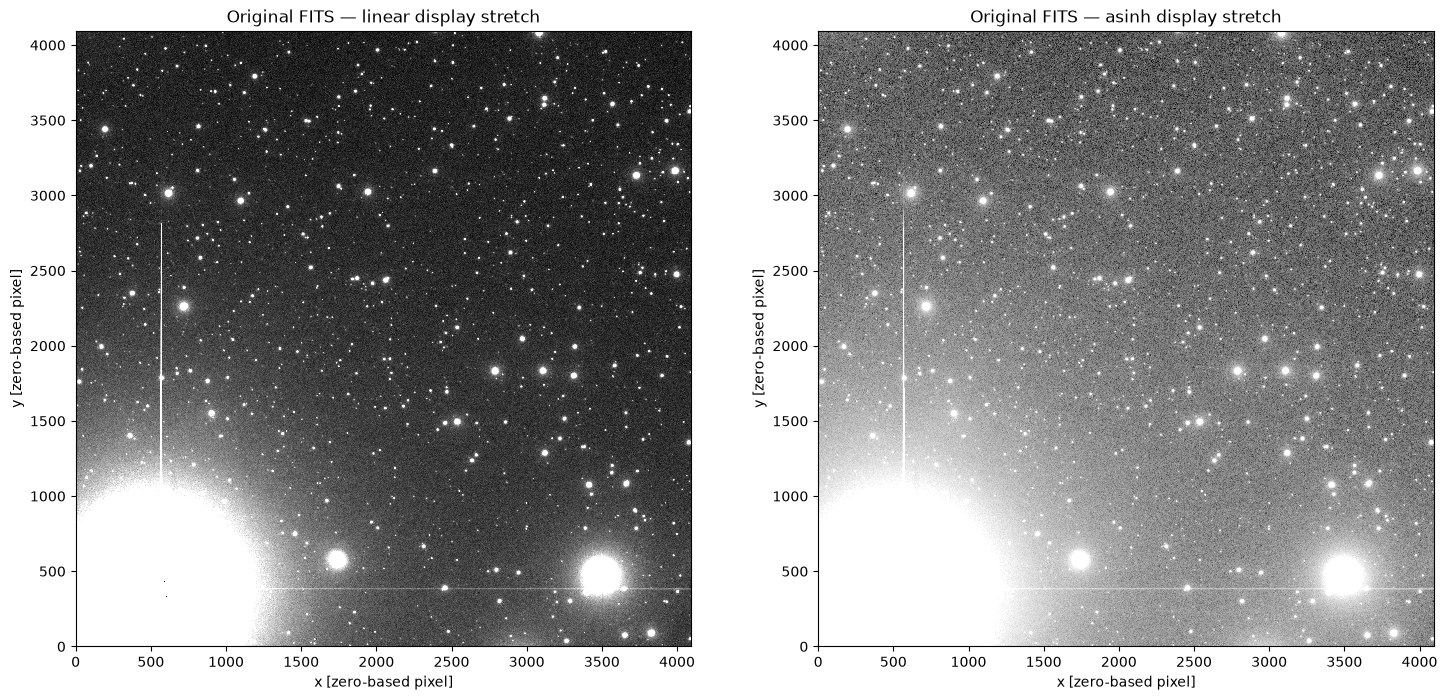

Raw display limits: -76.16918 275.79714962741383


In [ ]:
# Raw-frame visualization only. These limits remain the canonical raw-image display limits.
zscale = ZScaleInterval()
if DISPLAY_ZSCALE:
    display_vmin, display_vmax = zscale.get_limits(image_raw[valid_mask])
else:
    display_vmin, display_vmax = np.nanpercentile(image_raw[valid_mask], DISPLAY_PERCENTILES)
if not np.isfinite(display_vmin) or not np.isfinite(display_vmax):
    raise ValueError("Could not determine finite raw-image display limits.")
if display_vmax <= display_vmin:
    display_vmax = display_vmin + 1e-5

stretched_image_linear = np.clip(image_raw, display_vmin, display_vmax)
stretched_image_linear = (stretched_image_linear - display_vmin) / (display_vmax - display_vmin)

asinh_norm = ImageNormalize(
    image_raw,
    interval=ManualInterval(vmin=display_vmin, vmax=display_vmax),
    stretch=AsinhStretch(a=DISPLAY_ASINH_Q)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(
    stretched_image_linear, origin="lower", cmap="gray", interpolation="nearest",
    vmin=0, vmax=1
)
axes[0].set_title("Original FITS — linear display stretch")
axes[1].imshow(
    image_raw, origin="lower", cmap="gray", interpolation="nearest",
    norm=asinh_norm
)
axes[1].set_title("Original FITS — asinh display stretch")
for ax in axes:
    ax.set_xlabel("x [zero-based pixel]")
    ax.set_ylabel("y [zero-based pixel]")
plt.tight_layout()
plt.show()
print("Raw display limits:", display_vmin, display_vmax)


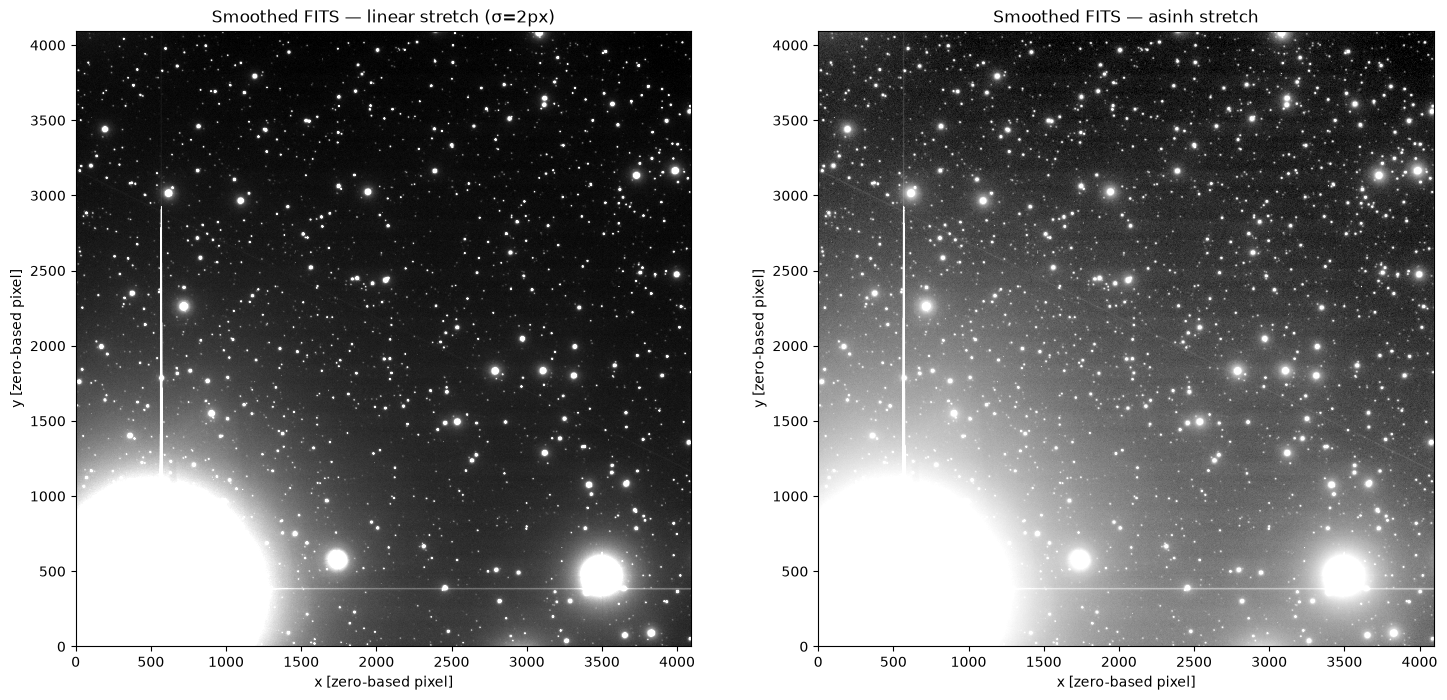

Display smoothing only; detector input remains the unsmoothed FITS/residual.


In [ ]:
# DS9-style smoothing is a visualization diagnostic ONLY.
# The smoothed image is never passed into the scientific detection pipeline.
kernel = Gaussian2DKernel(x_stddev=DISPLAY_SMOOTH_SIGMA_PIX)
image_smoothed = convolve(image_raw, kernel, nan_treatment="interpolate")

if DISPLAY_ZSCALE:
    smooth_display_vmin, smooth_display_vmax = zscale.get_limits(image_smoothed[valid_mask])
else:
    smooth_display_vmin, smooth_display_vmax = np.nanpercentile(image_smoothed[valid_mask], DISPLAY_PERCENTILES)
if not np.isfinite(smooth_display_vmin) or not np.isfinite(smooth_display_vmax):
    raise ValueError("Could not determine finite smoothed-image display limits.")
if smooth_display_vmax <= smooth_display_vmin:
    smooth_display_vmax = smooth_display_vmin + 1e-5

stretched_smoothed = np.clip(image_smoothed, smooth_display_vmin, smooth_display_vmax)
stretched_smoothed = (stretched_smoothed - smooth_display_vmin) / (smooth_display_vmax - smooth_display_vmin)
smooth_asinh_norm = ImageNormalize(
    image_smoothed,
    interval=ManualInterval(vmin=smooth_display_vmin, vmax=smooth_display_vmax),
    stretch=AsinhStretch(a=DISPLAY_ASINH_Q)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes[0].imshow(stretched_smoothed, origin="lower", cmap="gray", interpolation="nearest", vmin=0, vmax=1)
axes[0].set_title(f"Smoothed FITS — linear stretch (σ={DISPLAY_SMOOTH_SIGMA_PIX:g}px)")
axes[1].imshow(image_smoothed, origin="lower", cmap="gray", interpolation="nearest", norm=smooth_asinh_norm)
axes[1].set_title("Smoothed FITS — asinh stretch")
for ax in axes:
    ax.set_xlabel("x [zero-based pixel]")
    ax.set_ylabel("y [zero-based pixel]")
plt.tight_layout()
plt.show()
print("Display smoothing only; detector input remains the unsmoothed FITS/residual.")


## Stage 6 — Read and validate the two-edge DS9 IMAGE annotation

The annotation file must declare `image` and contain exactly two `line(x1,y1,x2,y2)` regions. These lines are the two manually drawn boundaries of the streak. DS9 IMAGE coordinates are one-based; conversion to zero-based pixel-centre coordinates is performed exactly once here.

In [5]:
region_text = EDGE_REGION_PATH.read_text(encoding="utf-8", errors="replace")

if not re.search(r"(?im)^\s*image\s*$", region_text):
    raise ValueError(
        f"{EDGE_REGION_PATH} must explicitly declare IMAGE coordinates. "
        "Re-save the two edge regions from DS9 with Coordinate System = Image."
    )

line_pattern = re.compile(
    r"line\s*\(\s*"
    r"([-+]?\d+(?:\.\d*)?(?:[eE][-+]?\d+)?)\s*,\s*"
    r"([-+]?\d+(?:\.\d*)?(?:[eE][-+]?\d+)?)\s*,\s*"
    r"([-+]?\d+(?:\.\d*)?(?:[eE][-+]?\d+)?)\s*,\s*"
    r"([-+]?\d+(?:\.\d*)?(?:[eE][-+]?\d+)?)\s*\)",
    re.IGNORECASE
)
line_values_ds9 = np.asarray(
    [tuple(map(float, match.groups())) for match in line_pattern.finditer(region_text)],
    dtype=float
)
if line_values_ds9.shape != (2, 4):
    raise ValueError(
        f"Expected exactly two DS9 edge lines, found shape {line_values_ds9.shape}."
    )

# DS9 IMAGE is 1-based; NumPy pixel-centre coordinates are 0-based.
edge_pixels = line_values_ds9.reshape(2, 2, 2) - 1.0
if not np.all(np.isfinite(edge_pixels)):
    raise ValueError("Non-finite coordinates in DS9 edge annotation.")

# Pair the two lines' endpoints so corresponding endpoints are closest.
direct_pairing = (
    np.linalg.norm(edge_pixels[0, 0] - edge_pixels[1, 0]) +
    np.linalg.norm(edge_pixels[0, 1] - edge_pixels[1, 1])
)
cross_pairing = (
    np.linalg.norm(edge_pixels[0, 0] - edge_pixels[1, 1]) +
    np.linalg.norm(edge_pixels[0, 1] - edge_pixels[1, 0])
)
if cross_pairing < direct_pairing:
    edge_pixels[1] = edge_pixels[1, ::-1]

centerline = 0.5 * (edge_pixels[0] + edge_pixels[1])
width_at_endpoints = np.linalg.norm(edge_pixels[0] - edge_pixels[1], axis=1)
edge_lengths = np.linalg.norm(edge_pixels[:, 1, :] - edge_pixels[:, 0, :], axis=1)
centerline_length = float(np.linalg.norm(centerline[1] - centerline[0]))

print("DS9 source lines (one-based):\n", line_values_ds9)
print("Converted edge endpoints (zero-based x,y):\n", edge_pixels)
print("Edge lengths [px]:", edge_lengths)
print("Endpoint separations [px]:", width_at_endpoints)
print("Mean annotation width [px]:", float(width_at_endpoints.mean()))
print("Centreline endpoints [px]:\n", centerline)
print("Centreline length [px]:", centerline_length)

DS9 source lines (one-based):
 [[  11.81788  3173.0774   4097.5021   1164.1898  ]
 [  10.565856 3164.5738   4096.2496   1155.6872  ]]
Converted edge endpoints (zero-based x,y):
 [[[  10.81788  3172.0774  ]
  [4096.5021   1163.1898  ]]

 [[   9.565856 3163.5738  ]
  [4095.2496   1154.6872  ]]]
Edge lengths [px]: [4552.85019905 4552.84933065]
Endpoint separations [px]: [8.59527644 8.59435646]
Mean annotation width [px]: 8.594816450727667
Centreline endpoints [px]:
 [[  10.191868 3167.8256  ]
 [4095.87585  1158.9385  ]]
Centreline length [px]: 4552.849764852535


## Stage 7 — Construct the finite annotation corridor and verify its footprint

The two manually drawn edges define a centreline and an approximate width that may vary linearly between corresponding endpoints. The corridor mask is created in row chunks to avoid allocating multiple full-frame coordinate grids.

This mask is a **manual annotation corridor**, not a detector output and not yet a physical PSF-width segmentation. It is used for visual QA and to prevent labelled trail pixels from contaminating the PSF-star sample. The truth-blind background estimator below does not use it.

In [6]:
def clip_segment_to_image_frt(p0, p1, nx, ny):
    """Liang–Barsky clip of an (x,y) segment to image bounds."""
    x0, y0 = map(float, p0)
    x1, y1 = map(float, p1)
    dx, dy = x1 - x0, y1 - y0
    p = (-dx, dx, -dy, dy)
    q = (x0, nx - 1 - x0, y0, ny - 1 - y0)
    t0, t1 = 0.0, 1.0
    for pi, qi in zip(p, q):
        if pi == 0:
            if qi < 0:
                return None
            continue
        r = qi / pi
        if pi < 0:
            t0 = max(t0, r)
        else:
            t1 = min(t1, r)
        if t0 > t1:
            return None
    return (
        np.array([x0 + t0 * dx, y0 + t0 * dy]),
        np.array([x0 + t1 * dx, y0 + t1 * dy])
    )


def build_corridor_mask(shape, segment, half_width_start, half_width_end, chunk_rows=None):
    """Rasterize a variable-width finite line corridor in row chunks."""
    if chunk_rows is None:
        chunk_rows = CHUNK_ROWS
    height, width = shape
    p0, p1 = np.asarray(segment, dtype=float)
    vx, vy = p1 - p0
    length2 = vx * vx + vy * vy
    length = np.sqrt(length2)
    if length <= 0:
        raise ValueError("Annotation centreline has zero length.")

    mask = np.zeros(shape, dtype=bool)
    x = np.arange(width, dtype=np.float64)[None, :]

    for y0 in range(0, height, chunk_rows):
        y1 = min(y0 + chunk_rows, height)
        y = np.arange(y0, y1, dtype=np.float64)[:, None]
        dx = x - p0[0]
        dy = y - p0[1]
        t = (dx * vx + dy * vy) / length2
        t_clipped = np.clip(t, 0.0, 1.0)
        # Perpendicular distance to the infinite line, restricted to the finite segment.
        d_perp = np.abs(dx * vy - dy * vx) / length
        half_width = half_width_start + (half_width_end - half_width_start) * t_clipped
        in_segment = (t >= 0.0) & (t <= 1.0)
        mask[y0:y1] = in_segment & (d_perp <= half_width)
    return mask

clipped_centerline = clip_segment_to_image_frt(centerline[0], centerline[1], nx, ny)
if clipped_centerline is None:
    raise ValueError(
        "The IMAGE-coordinate annotation does not intersect this FITS image. "
        "Check that the DS9 region was saved against this exact frame."
    )

annotation_mask = build_corridor_mask(
    image_raw.shape,
    centerline,
    half_width_start=float(width_at_endpoints[0] / 2),
    half_width_end=float(width_at_endpoints[1] / 2),
    chunk_rows=CHUNK_ROWS
)
annotation_mask &= valid_mask

annotation_pixel_count = int(annotation_mask.sum())
annotation_fraction = float(annotation_mask.mean())
print("Visible clipped centreline:", clipped_centerline)
print("Annotation mask pixels:", annotation_pixel_count)
print("Annotation mask fraction:", annotation_fraction)

if annotation_pixel_count == 0:
    raise ValueError("Annotation mask is empty. Stop and correct the annotation geometry.")
if annotation_pixel_count < 100:
    warnings.warn("Annotation mask is unexpectedly small for this long edge annotation.")

Visible clipped centreline: (array([  10.191868, 3167.8256  ]), array([4095.        , 1159.36914607]))
Annotation mask pixels: 39125
Annotation mask fraction: 0.002332031726837158


## Stage 8 — Annotation visualization and local inspection

A full-frame overlay verifies global geometry; three local crops check that both edges actually bracket the same faint feature. The displayed image values are unchanged; only the rendering stretch is applied.

NameError: name 'display_vmin' is not defined

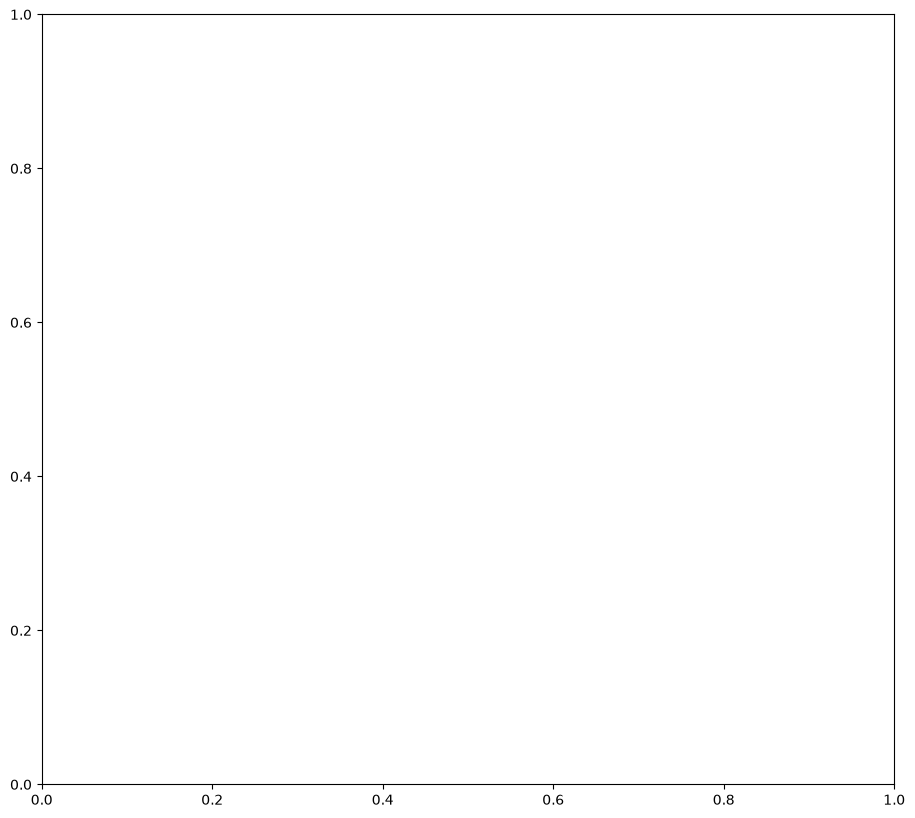

In [7]:
fig, ax = plt.subplots(figsize=(11, 10))
ax.imshow(
    image_raw, origin="lower", cmap="gray", interpolation="nearest",
    vmin=display_vmin, vmax=display_vmax
)
ax.plot(edge_pixels[0, :, 0], edge_pixels[0, :, 1], linewidth=1.4, label="Manual edge 1")
ax.plot(edge_pixels[1, :, 0], edge_pixels[1, :, 1], linewidth=1.4, label="Manual edge 2")
ax.plot(centerline[:, 0], centerline[:, 1], "--", linewidth=1.2, label="Derived centreline")
ax.contour(annotation_mask.astype(np.uint8), levels=[0.5], linewidths=0.7)
ax.set_xlim(0, nx - 1)
ax.set_ylim(0, ny - 1)
ax.set_aspect("equal")
ax.set_title(f"{FRAME_FILENAME} — verified manual annotation overlay")
ax.set_xlabel("x [zero-based image pixel]")
ax.set_ylabel("y [zero-based image pixel]")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

# Inspect representative portions of the annotated line.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, t in zip(axes, (0.20, 0.50, 0.80)):
    point = centerline[0] + t * (centerline[1] - centerline[0])
    cx, cy = point
    half = ANNOTATION_CROP_HALF_SIZE
    xlo, xhi = max(0, int(cx-half)), min(nx, int(cx+half))
    ylo, yhi = max(0, int(cy-half)), min(ny, int(cy+half))
    ax.imshow(
        image_raw[ylo:yhi, xlo:xhi], origin="lower", cmap="gray",
        interpolation="nearest", vmin=display_vmin, vmax=display_vmax,
        extent=(xlo, xhi, ylo, yhi)
    )
    ax.plot(edge_pixels[0, :, 0], edge_pixels[0, :, 1], linewidth=1.1)
    ax.plot(edge_pixels[1, :, 0], edge_pixels[1, :, 1], linewidth=1.1)
    ax.plot(centerline[:, 0], centerline[:, 1], "--", linewidth=1.0)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(ylo, yhi)
    ax.set_title(f"Trail crop at t={t:.2f}")
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")
plt.tight_layout()
plt.show()

### Manual acceptance gate — do not skip

Inspect the full-frame overlay and the three crops. Continue only if:

- both edge lines follow the same visible feature;
- the centreline lies between the edges;
- the edge separation is plausible and stable;
- the annotation mask overlays the feature rather than adjacent stars or background;
- the edge geometry belongs to this exact FITS frame.

If this fails, correct the DS9 IMAGE annotation. Do not compensate by shifting the label in Python.

## Stage 9 — Background and local-RMS mesh sensitivity

We compare SEP mesh sizes 32, 64 and 128 pixels using the same raw image and the same invalid-pixel mask. The annotation corridor is **not** passed to SEP: this keeps the background estimator independent of the known label and mirrors how the later unlabeled 85-frame pipeline must operate.

SEP estimates a spatial background and local RMS on a mesh, then interpolates the maps. These are practical estimators, not unique values prescribed by Nir et al. The mesh choice must be justified by inspecting whether broad gradients remain and whether the estimated background starts following stellar halos or faint extended features.

In [8]:
# Convert once to native-endian contiguous float32 for SEP.
sep_image = np.ascontiguousarray(image_raw, dtype=np.float32)
sep_image[~valid_mask] = 0.0
sep_bad_mask = ~valid_mask

background_trials = {}
rms_trials = {}
residual_trials = {}
background_rows = []

for mesh in BG_MESH_OPTIONS:
    estimator = sep.Background(
        sep_image,
        mask=sep_bad_mask,
        bw=int(mesh), bh=int(mesh),
        fw=int(BG_FILTER_SIZE), fh=int(BG_FILTER_SIZE)
    )
    bkg_map = np.asarray(estimator.back(), dtype=np.float32)
    rms_map_trial = np.asarray(estimator.rms(), dtype=np.float32)
    residual_trial = image_raw.astype(np.float32) - bkg_map

    rms_map_trial[(~np.isfinite(rms_map_trial)) | (rms_map_trial <= 0)] = np.nan
    background_trials[mesh] = bkg_map
    rms_trials[mesh] = rms_map_trial
    residual_trials[mesh] = residual_trial

    rv = residual_trial[valid_mask & np.isfinite(residual_trial)]
    med_r = float(np.median(rv))
    mad_r = float(1.4826 * np.median(np.abs(rv - med_r)))
    rmsv = rms_map_trial[np.isfinite(rms_map_trial)]
    background_rows.append({
        "mesh_pixels": int(mesh),
        "background_median": float(np.nanmedian(bkg_map)),
        "background_p10": float(np.nanpercentile(bkg_map, 10)),
        "background_p90": float(np.nanpercentile(bkg_map, 90)),
        "residual_median": med_r,
        "residual_global_MAD_sigma": mad_r,
        "local_RMS_median": float(np.nanmedian(rmsv)),
        "local_RMS_p10": float(np.nanpercentile(rmsv, 10)),
        "local_RMS_p90": float(np.nanpercentile(rmsv, 90))
    })

background_comparison = pd.DataFrame(background_rows).set_index("mesh_pixels")
display(background_comparison)

if BG_MESH_SIZE not in background_trials:
    raise ValueError(f"BG_MESH_SIZE={BG_MESH_SIZE} not in BG_MESH_OPTIONS={BG_MESH_OPTIONS}.")

,background_median,background_p10,background_p90,residual_median,residual_global_MAD_sigma,local_RMS_median,local_RMS_p10,local_RMS_p90
mesh_pixels,,,,,,,,
32,-3.789433,-27.177933,158.093719,1.359591,19.038614,17.384300,16.884830,20.732231
64,-4.267338,-27.023691,153.262131,1.850211,19.423889,17.580214,17.087616,22.203926
128,-4.286509,-26.569679,138.429352,2.570759,20.143158,17.838669,17.285656,27.039276


## Stage 10 — Visual comparison of background trials

Use a common display range for each set of maps so that apparent differences are not caused by changing plot limits. The residual panels use a symmetric scale based on the selected trial's typical RMS. This is a visualization choice only.

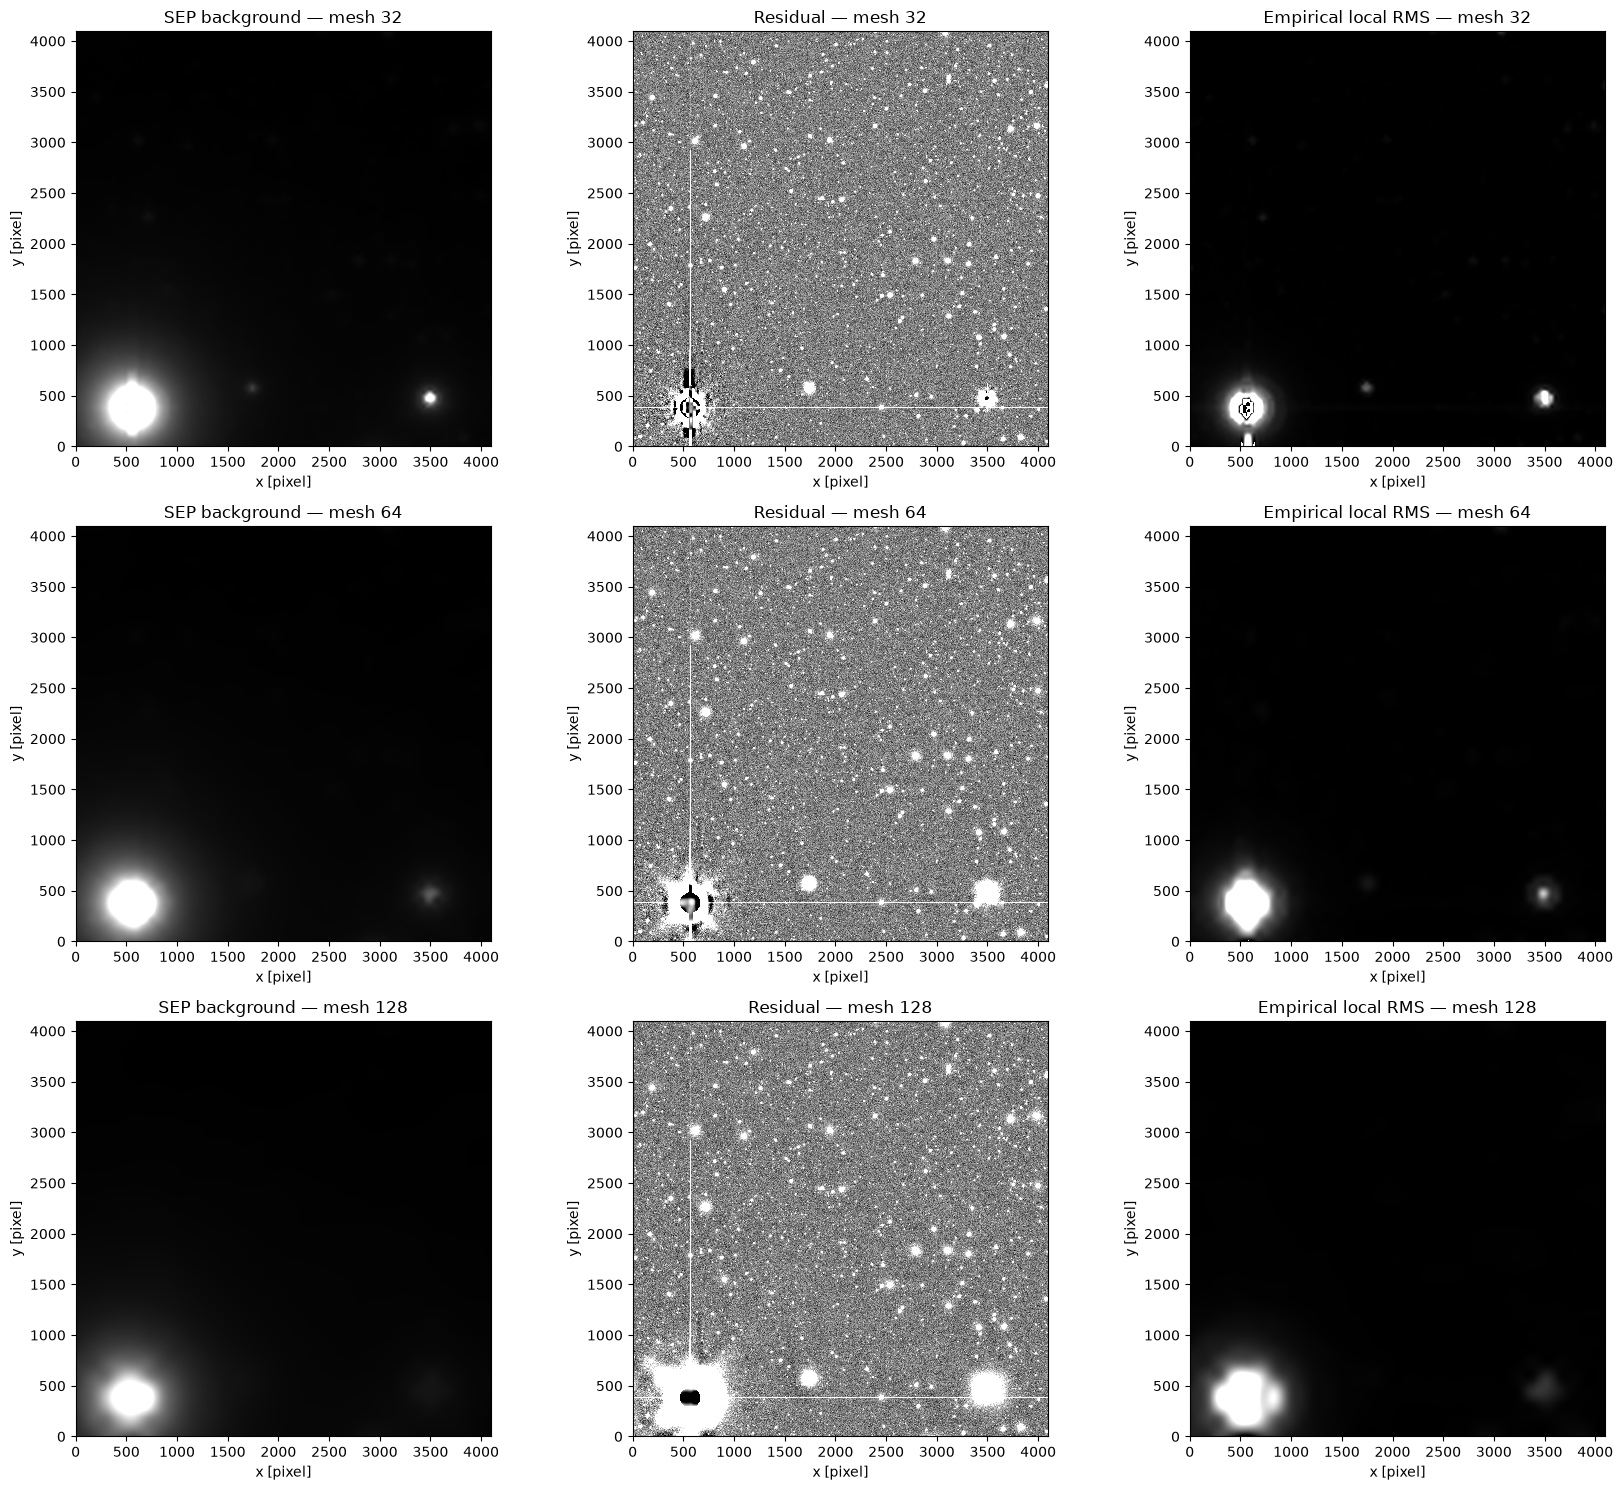

In [9]:
# Build shared display limits across the three mesh alternatives.
bg_limits = [
    np.nanpercentile(background_trials[m][valid_mask], [1, 99])
    for m in BG_MESH_OPTIONS
]
rms_limits = [
    np.nanpercentile(rms_trials[m][np.isfinite(rms_trials[m])], [1, 99])
    for m in BG_MESH_OPTIONS
]

background_vmin = float(min(v[0] for v in bg_limits))
background_vmax = float(max(v[1] for v in bg_limits))
rms_vmin = float(min(v[0] for v in rms_limits))
rms_vmax = float(max(v[1] for v in rms_limits))
residual_scale_common = RESIDUAL_DISPLAY_RMS_MULTIPLIER * max(
    float(np.nanmedian(rms_trials[m])) for m in BG_MESH_OPTIONS
)

fig, axes = plt.subplots(
    len(BG_MESH_OPTIONS), 3,
    figsize=(17, 5 * len(BG_MESH_OPTIONS)),
    squeeze=False
)

for row, mesh in enumerate(BG_MESH_OPTIONS):
    bkg_map = background_trials[mesh]
    rms_map_trial = rms_trials[mesh]
    residual_trial = residual_trials[mesh]

    axes[row, 0].imshow(
        bkg_map, origin="lower", cmap="gray",
        vmin=background_vmin, vmax=background_vmax,
        interpolation="nearest"
    )
    axes[row, 0].set_title(f"SEP background — mesh {mesh}")

    axes[row, 1].imshow(
        residual_trial, origin="lower", cmap="gray",
        vmin=-residual_scale_common, vmax=residual_scale_common,
        interpolation="nearest"
    )
    axes[row, 1].set_title(f"Residual — mesh {mesh}")

    axes[row, 2].imshow(
        rms_map_trial, origin="lower", cmap="gray",
        vmin=rms_vmin, vmax=rms_vmax,
        interpolation="nearest"
    )
    axes[row, 2].set_title(f"Empirical local RMS — mesh {mesh}")

    for ax in axes[row]:
        ax.set_xlabel("x [pixel]")
        ax.set_ylabel("y [pixel]")

plt.tight_layout()
plt.show()


**What do the mesh, background and residual results mean?**

* What is mesh 32, 64 or 128?

Our 4096 × 4096 image is divided into smaller boxes for SEP's background estimation.

| Mesh | Number of boxes along an axis | Approximate total boxes |
|---:|---:|---:|
| 32 × 32 px | 128 | 16,384 |
| 64 × 64 px | 64 | 4,096 |
| 128 × 128 px | 32 | 1,024 |


SEP estimates the background and RMS on this grid and interpolates the result to the full image. Its bw and bh parameters specify box dimensions in pixels, while fw and fh specify the filtering size in mesh boxes. (SEP Background documentation)

Think of the background as a slowly varying landscape.

A small mesh follows that landscape more closely, but can also follow stellar halos and other local structures.

A large mesh produces a smoother estimate, but can miss smaller spatial variations.

* What is the Residual Image?

The residual image is the background-subtracted data array. Mathematically, it is defined as:

\(R(x,y)=I(x,y)-B(x,y)\)

Where:

• \(I(x,y)\) = Original FITS image

• \(B(x,y)\) = Estimated background map

• \(R(x,y)\) = Background-subtracted residual

Important Note: This is not a streak-only image. Stars, cosmic rays, structural artifacts, noise, and genuine streaks all remain in the data.

* What is the RMS Map?

The Root Mean Square (RMS) map estimates the local background fluctuation level across the frame:

$$\sigma_{\mathrm{local}}(x,y)$$

Squaring this map provides our empirical variance proxy:

$$V_{\mathrm{proxy}}(x,y) = \sigma_{\mathrm{local}}(x,y)^{2}$$

• Purpose: This enables us to normalize candidate line scores against spatially varying noise.

• Limitation: This is not a calibrated total detector variance. 

Our FITS header does not provide verified gain and read-noise values, and this model does not account for every possible noise correlation or source Poisson noise contribution.

## Stage 11 — Select one background model and create canonical preprocessing arrays

`BG_MESH_SIZE` in the configuration is the only selection point. The default 64 pixels is provisional, not claimed optimal. After reviewing Stage 10, change it once if needed and rerun from this stage onward.

The output `variance_background_proxy = rms_map**2` describes empirical local background variance. There are no verified GAIN/RDNOISE cards in the target-file audit, and the stored image appears to have a near-zero median. Therefore this notebook does **not** invent a Poisson-plus-read-noise calibration or add a header sky pedestal. A calibrated detector variance model requires verified calibration conventions and the correct pre-subtraction count level.

In [10]:
background_map = background_trials[BG_MESH_SIZE].copy()
rms_map = rms_trials[BG_MESH_SIZE].copy()
residual_image = residual_trials[BG_MESH_SIZE].copy()

bad_variance_mask = (~valid_mask) | (~np.isfinite(rms_map)) | (rms_map <= 0)
analysis_valid_mask = ~bad_variance_mask
variance_background_proxy = np.where(
    analysis_valid_mask,
    rms_map.astype(np.float64) ** 2,
    np.nan
).astype(np.float32)

if not np.any(analysis_valid_mask):
    raise RuntimeError("No valid pixels remain in the empirical RMS/variance map.")

print("Selected background mesh:", BG_MESH_SIZE)
print("Background median:", float(np.nanmedian(background_map)))
print("Residual median:", float(np.nanmedian(residual_image)))
print("Empirical local RMS median:", float(np.nanmedian(rms_map)))
print("Empirical local RMS P10/P90:", np.nanpercentile(rms_map, [10, 90]))
print("Valid variance fraction:", float(analysis_valid_mask.mean()))
print("Variance label: empirical background variance proxy, not calibrated total detector variance")

Selected background mesh: 64
Background median: -4.267338275909424
Residual median: 1.8502111434936523
Empirical local RMS median: 17.58021354675293
Empirical local RMS P10/P90: [17.08761597 22.20392609]
Valid variance fraction: 0.999955415725708
Variance label: empirical background variance proxy, not calibrated total detector variance


## Stage 12 — Residual statistics near and away from the annotated trail

This comparison is diagnostic only. It checks whether the local RMS/background around the label behaves differently from nearby off-trail pixels. It is not used to choose the background mesh or tune the detector threshold.

Bright stars can contaminate the nearby off-trail sample; report robust statistics and inspect the local crop rather than treating this as a formal noise-only sample.

In [11]:
def robust_summary(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return {"n": 0, "median": np.nan, "MAD_sigma": np.nan, "p10": np.nan, "p90": np.nan}
    med = float(np.median(values))
    return {
        "n": int(values.size),
        "median": med,
        "MAD_sigma": float(1.4826 * np.median(np.abs(values - med))),
        "p10": float(np.percentile(values, 10)),
        "p90": float(np.percentile(values, 90))
    }

# Construct a near-trail control corridor with a larger radius, using chunks.
near_trail_mask = np.zeros(image_raw.shape, dtype=bool)
p0, p1 = centerline
vx, vy = p1 - p0
length2 = vx*vx + vy*vy
x_axis = np.arange(nx, dtype=float)[None, :]
for y0 in range(0, ny, CHUNK_ROWS):
    y1 = min(y0 + CHUNK_ROWS, ny)
    y_axis = np.arange(y0, y1, dtype=float)[:, None]
    dx = x_axis - p0[0]
    dy = y_axis - p0[1]
    t = (dx*vx + dy*vy) / length2
    tclip = np.clip(t, 0, 1)
    d = np.hypot(dx - tclip*vx, dy - tclip*vy)
    near_trail_mask[y0:y1] = (t >= 0) & (t <= 1) & (d <= LOCAL_CONTROL_HALF_WIDTH_PIX)

on_trail = annotation_mask & analysis_valid_mask
near_off_trail = near_trail_mask & (~annotation_mask) & analysis_valid_mask

local_stats = pd.DataFrame({
    "residual": {
        "annotated_corridor": robust_summary(residual_image[on_trail])["median"],
        "nearby_off_trail": robust_summary(residual_image[near_off_trail])["median"]
    },
    "local_RMS": {
        "annotated_corridor": robust_summary(rms_map[on_trail])["median"],
        "nearby_off_trail": robust_summary(rms_map[near_off_trail])["median"]
    }
})
display(local_stats)
print("Residual summary — annotated corridor:", robust_summary(residual_image[on_trail]))
print("Residual summary — nearby off-trail:", robust_summary(residual_image[near_off_trail]))
print("RMS summary — annotated corridor:", robust_summary(rms_map[on_trail]))
print("RMS summary — nearby off-trail:", robust_summary(rms_map[near_off_trail]))

,residual,local_RMS
annotated_corridor,5.834907,17.481812
nearby_off_trail,1.057643,17.476986


Residual summary — annotated corridor: {'n': 39125, 'median': 5.834907054901123, 'MAD_sigma': 19.077895361995697, 'p10': -17.563317108154298, 'p90': 33.4939224243164}
Residual summary — nearby off-trail: {'n': 324630, 'median': 1.057643473148346, 'MAD_sigma': 18.49925667772293, 'p10': -21.911648559570313, 'p90': 27.15448226928711}
RMS summary — annotated corridor: {'n': 39125, 'median': 17.4818115234375, 'MAD_sigma': 0.41370661697387695, 'p10': 17.085323333740234, 'p90': 18.05184860229492}
RMS summary — nearby off-trail: {'n': 324630, 'median': 17.476985931396484, 'MAD_sigma': 0.3894720703125, 'p10': 17.078285217285156, 'p90': 18.093417930603028}


## Stage 13 — Build a source catalogue for PSF-star selection

SEP source extraction is run on the background-subtracted residual using the empirical local RMS as its detection-error map. The annotation corridor is masked **only for PSF-star selection** so that the labelled trail is not mistaken for a stellar profile. This does not mask the trail from a future streak detector.

SEP's ellipse moments (`a`, `b`, `theta`) are useful for candidate selection, but they are not accepted as the final PSF measurement. We fit the pixel profiles of isolated candidate stars in the next stage.

In [12]:
residual_sep = np.ascontiguousarray(residual_image, dtype=np.float32)
rms_sep = np.ascontiguousarray(rms_map, dtype=np.float32)
psf_source_mask = (~analysis_valid_mask) | annotation_mask

# SEP receives finite arrays even at masked pixels. Invalid pixels are masked
# and assigned neutral finite placeholders rather than NaN/Inf error values.
residual_sep[~analysis_valid_mask] = 0.0
rms_fill = float(np.nanmedian(rms_map[analysis_valid_mask]))
rms_sep[~analysis_valid_mask] = rms_fill

objects = sep.extract(
    residual_sep,
    thresh=SOURCE_DETECT_THRESHOLD,
    err=rms_sep,
    mask=psf_source_mask,
    minarea=SOURCE_MIN_AREA,
    deblend_nthresh=32,
    deblend_cont=0.005,
    clean=True
)

print("SEP source detections:", len(objects))
if len(objects) == 0:
    raise RuntimeError("SEP found no sources; inspect residual/RMS and detection settings.")

required = {"x", "y", "a", "b", "theta", "flux", "peak", "flag"}
missing = required.difference(objects.dtype.names)
if missing:
    raise RuntimeError(f"SEP catalogue missing fields: {sorted(missing)}")

SEP source detections: 1502


## Stage 14 — Select isolated, unsaturated-looking PSF candidates

This is a provisional selection prior to direct profile fitting. It uses roundness, finite positive flux, extraction flags, a peak/flux range, nearest-neighbour isolation and enough margin for a full cutout.

If a saturation threshold exists in the FITS header it is used. If it does not, the upper peak/flux quantile is excluded as a conservative proxy; that does **not** prove remaining sources are unsaturated.

In [13]:
src_x = np.asarray(objects["x"], dtype=float)
src_y = np.asarray(objects["y"], dtype=float)
src_a = np.asarray(objects["a"], dtype=float)
src_b = np.asarray(objects["b"], dtype=float)
src_flux = np.asarray(objects["flux"], dtype=float)
src_peak = np.asarray(objects["peak"], dtype=float)
src_flags = np.asarray(objects["flag"])

src_size = np.sqrt(np.maximum(src_a, 0) * np.maximum(src_b, 0))
axis_ratio = np.divide(
    np.minimum(src_a, src_b), np.maximum(src_a, src_b),
    out=np.zeros_like(src_a), where=np.maximum(src_a, src_b) > 0
)

finite_source = (
    np.isfinite(src_x) & np.isfinite(src_y) &
    np.isfinite(src_a) & np.isfinite(src_b) &
    np.isfinite(src_flux) & np.isfinite(src_peak) &
    (src_a > 0) & (src_b > 0) & (src_flux > 0)
)
inside_cutout = (
    (src_x >= PSF_CUTOUT_HALF_SIZE) &
    (src_x < nx - PSF_CUTOUT_HALF_SIZE) &
    (src_y >= PSF_CUTOUT_HALF_SIZE) &
    (src_y < ny - PSF_CUTOUT_HALF_SIZE)
)

# Isolation: nearest neighbour must be farther than both a minimum pixel
# distance and four times the candidate's larger SEP moment axis.
coords = np.column_stack([src_x[finite_source], src_y[finite_source]])
if len(coords) >= 2:
    nn_dist, _ = cKDTree(coords).query(coords, k=2)
    nn_all = np.full(len(objects), np.nan)
    nn_all[np.flatnonzero(finite_source)] = nn_dist[:, 1]
else:
    nn_all = np.full(len(objects), np.nan)

flux_good = src_flux[finite_source]
peak_good = src_peak[finite_source]
flux_lo, flux_hi = np.percentile(flux_good, PSF_FLUX_QUANTILES)

sat_level = header.get("SATURATE", None)
if sat_level is not None and np.isfinite(float(sat_level)):
    not_saturated = src_peak < 0.9 * float(sat_level)
    saturation_rule = f"peak < 0.9 * SATURATE ({sat_level})"
else:
    peak_limit = float(np.percentile(peak_good, 95))
    not_saturated = src_peak < peak_limit
    saturation_rule = f"peak below 95th percentile ({peak_limit:.3g}); proxy only"

psf_candidate_mask = (
    finite_source & inside_cutout &
    (src_flags == 0) &
    (axis_ratio >= PSF_AXIS_RATIO_MIN) &
    (src_flux >= flux_lo) & (src_flux <= flux_hi) &
    not_saturated &
    np.isfinite(nn_all) &
    (nn_all >= np.maximum(PSF_NEIGHBOUR_MIN_PIX, 4.0*np.maximum(src_a, src_b)))
)
psf_candidate_indices = np.flatnonzero(psf_candidate_mask)

print("Saturation handling:", saturation_rule)
print("Flux interval:", (float(flux_lo), float(flux_hi)))
print("PSF candidates after morphology/isolation cuts:", len(psf_candidate_indices))

if len(psf_candidate_indices) < 20:
    warnings.warn("Fewer than 20 PSF candidates: empirical PSF may be poorly constrained.")

# Deterministic random subset for bounded fitting cost.
rng = np.random.default_rng(PSF_RANDOM_SEED)
if len(psf_candidate_indices) > MAX_PSF_FITS:
    fit_indices = np.sort(rng.choice(psf_candidate_indices, MAX_PSF_FITS, replace=False))
else:
    fit_indices = psf_candidate_indices.copy()
print("Stars selected for 2-D Gaussian fitting:", len(fit_indices))

Saturation handling: peak below 95th percentile (7.65e+03); proxy only
Flux interval: (10468.5869140625, 267751.99062500003)
PSF candidates after morphology/isolation cuts: 718
Stars selected for 2-D Gaussian fitting: 200


## Stage 15 — Fit stellar cutouts with a 2-D elliptical Gaussian plus local plane

For each selected source, fit the **background-subtracted original residual pixels** with an elliptical Gaussian and a local planar residual background. The fit is weighted by the empirical RMS map and uses a robust `soft_l1` loss.

The Gaussian fit is a first-order PSF diagnostic. Real astronomical PSFs can have non-Gaussian wings, asymmetry and spatial variation. We therefore inspect fit residuals and spatial distributions before accepting a median width. SEP moments are not substituted for failed fits.

In [14]:
def elliptical_gaussian_plane(params, x, y):
    amp, x0, y0, sigma_x, sigma_y, theta, b0, bx, by = params
    dx = x - x0
    dy = y - y0
    ct, st = np.cos(theta), np.sin(theta)
    xr = ct * dx + st * dy
    yr = -st * dx + ct * dy
    gaussian = amp * np.exp(-0.5 * ((xr / sigma_x)**2 + (yr / sigma_y)**2))
    return b0 + bx * dx + by * dy + gaussian


def fit_psf_star(image, rms, x_source, y_source, a_seed, b_seed, theta_seed,
                 half_size=None, sigma_bounds=None):
    """Fit one isolated stellar cutout with a robust weighted elliptical Gaussian plus plane."""
    if half_size is None:
        half_size = PSF_CUTOUT_HALF_SIZE
    if sigma_bounds is None:
        sigma_bounds = PSF_FIT_SIGMA_BOUNDS
    x_int, y_int = int(round(x_source)), int(round(y_source))
    x0, x1 = x_int-half_size, x_int+half_size+1
    y0, y1 = y_int-half_size, y_int+half_size+1
    cut = np.asarray(image[y0:y1, x0:x1], dtype=float)
    err = np.asarray(rms[y0:y1, x0:x1], dtype=float)
    if cut.shape != (2*half_size+1, 2*half_size+1):
        return None
    good = np.isfinite(cut) & np.isfinite(err) & (err > 0)
    if good.mean() < 0.98:
        return None

    yy, xx = np.indices(cut.shape, dtype=float)
    xx = xx[good]
    yy = yy[good]
    z = cut[good]
    e = err[good]

    border = np.concatenate([cut[0, :], cut[-1, :], cut[:, 0], cut[:, -1]])
    b0 = float(np.median(border))
    noise0 = float(np.median(e))
    amp0 = float(np.nanmax(cut) - b0)
    if not np.isfinite(amp0) or amp0 <= 0 or noise0 <= 0:
        return None

    x0_local = float(x_source - x0)
    y0_local = float(y_source - y0)
    sigma_min, sigma_max = map(float, sigma_bounds)
    if not (0 < sigma_min < sigma_max):
        raise ValueError("sigma_bounds must satisfy 0 < lower < upper.")
    sx0 = float(np.clip(a_seed, sigma_min * 1.1, sigma_max * 0.9))
    sy0 = float(np.clip(b_seed, sigma_min * 1.1, sigma_max * 0.9))
    th0 = float(np.clip(theta_seed, -np.pi/2, np.pi/2))

    p0 = np.array([amp0, x0_local, y0_local, sx0, sy0, th0, b0, 0.0, 0.0])
    lower = np.array([0.0, x0_local-2.0, y0_local-2.0, sigma_min, sigma_min, -np.pi/2,
                      b0-5*noise0, -noise0, -noise0])
    upper = np.array([np.inf, x0_local+2.0, y0_local+2.0, sigma_max, sigma_max, np.pi/2,
                      b0+5*noise0, noise0, noise0])

    def residual(params):
        return (elliptical_gaussian_plane(params, xx, yy) - z) / e

    try:
        result = least_squares(
            residual, p0, bounds=(lower, upper),
            loss="soft_l1", f_scale=1.0, max_nfev=800
        )
    except Exception:
        return None

    if not result.success:
        return None

    amp, xf, yf, sx, sy, theta, bg, bx, by = result.x
    if not (sigma_min < sx < sigma_max and sigma_min < sy < sigma_max):
        return None

    norm_resid = residual(result.x)
    dof = max(len(norm_resid) - len(result.x), 1)
    reduced_chi2 = float(np.sum(norm_resid**2) / dof)
    sigma_major = float(max(sx, sy))
    sigma_minor = float(min(sx, sy))
    sigma_geom = float(np.sqrt(sx * sy))

    return {
        "x": float(x_source), "y": float(y_source),
        "amplitude": float(amp),
        "sigma_x_fit": float(sx), "sigma_y_fit": float(sy),
        "sigma_major": sigma_major, "sigma_minor": sigma_minor,
        "sigma_geom": sigma_geom,
        "fwhm_major": 2.354820045 * sigma_major,
        "fwhm_minor": 2.354820045 * sigma_minor,
        "theta_rad": float(theta),
        "peak_to_local_rms": float(amp / noise0),
        "reduced_chi2": reduced_chi2,
        "success": True
    }

fit_rows = []
for idx in fit_indices:
    fit = fit_psf_star(
        residual_image, rms_map,
        src_x[idx], src_y[idx],
        src_a[idx], src_b[idx], objects["theta"][idx],
        half_size=PSF_CUTOUT_HALF_SIZE,
        sigma_bounds=PSF_FIT_SIGMA_BOUNDS
    )
    if fit is not None:
        fit["sep_index"] = int(idx)
        fit["sep_flux"] = float(src_flux[idx])
        fit["sep_flag"] = int(src_flags[idx])
        fit_rows.append(fit)

psf_fit_table = pd.DataFrame(fit_rows)
print("Successful 2-D PSF fits:", len(psf_fit_table), "of", len(fit_indices))
if len(psf_fit_table):
    display(psf_fit_table.head(10))
else:
    raise RuntimeError(
        "No stellar cutouts produced valid Gaussian fits. Inspect source selection, "
        "RMS map and residual image; do not fall back to SEP moment widths."
    )

Successful 2-D PSF fits: 200 of 200


,x,y,amplitude,sigma_x_fit,sigma_y_fit,sigma_major,sigma_minor,sigma_geom,fwhm_major,fwhm_minor,theta_rad,peak_to_local_rms,reduced_chi2,success,sep_index,sep_flux,sep_flag
0,1765.701283,27.622749,286.108740,3.476332,3.034278,3.476332,3.034278,3.247793,8.186137,7.145178,-1.074075,15.765890,0.985876,True,13,16705.726562,0
1,1865.690402,101.750005,207.778721,3.382960,2.982178,3.382960,2.982178,3.176254,7.966261,7.022492,-0.629263,11.637192,0.950670,True,34,11166.694336,0
2,2689.680831,127.631706,317.692023,3.372452,3.033287,3.372452,3.033287,3.198377,7.941518,7.142845,-0.930101,17.801149,1.047149,True,44,18904.605469,0
3,1576.864397,167.742684,223.428515,3.081591,3.444658,3.444658,3.081591,3.258071,8.111550,7.256592,0.750778,11.753140,0.977412,True,49,12404.375000,0
4,2364.751145,196.175341,411.285428,3.411152,3.116106,3.411152,3.116106,3.260293,8.032649,7.337869,-0.566162,23.465375,1.130611,True,57,26027.511719,0
5,1222.792656,334.269190,634.411075,3.505459,3.127045,3.505459,3.127045,3.310850,8.254726,7.363628,-1.007690,24.991041,0.676892,True,79,41636.367188,0
6,997.336200,410.844506,1555.094964,3.513579,3.105809,3.513579,3.105809,3.303408,8.273845,7.313621,-0.901863,27.762610,0.256485,True,87,103254.359375,0
7,1479.348931,499.456967,351.486437,3.421700,3.152628,3.421700,3.152628,3.284410,8.057489,7.423872,-0.615927,17.625507,0.857151,True,101,22345.296875,0
8,2049.844780,518.661093,417.858905,3.360410,3.060493,3.360410,3.060493,3.206947,7.913160,7.206911,-0.844677,23.667383,1.057758,True,109,26197.912109,0
9,1914.362738,520.773566,738.691066,3.448331,3.078395,3.448331,3.078395,3.258117,8.120198,7.249066,-0.721090,40.314287,1.219280,True,111,51059.039062,0


## Stage 16 — PSF fit quality, spatial stability and kernel visualization

We summarize only successful fits. A conservative diagnostic cut rejects fits with low peak-to-local-RMS or extreme reduced chi-square. This cut is for PSF estimation, not for streak-candidate validation.

A single circular Gaussian is retained only as a compact approximation for the next detector baseline. If the fitted widths are spatially variable or strongly elliptical, a spatially varying or empirical PSF model will be required.

Fits passing diagnostic quality cuts: 192 of 200
Median geometric PSF sigma: 3.291 px
Equivalent circular-Gaussian FWHM: 7.750 px
Median fitted major sigma: 3.440 px
Median fitted minor sigma: 3.150 px
Header FWHM card: 2.5201002281347624
Header IMSCALE card: 0.3276
Conditional header-derived FWHM: 7.693 px
Fitted/header FWHM ratio: 1.008


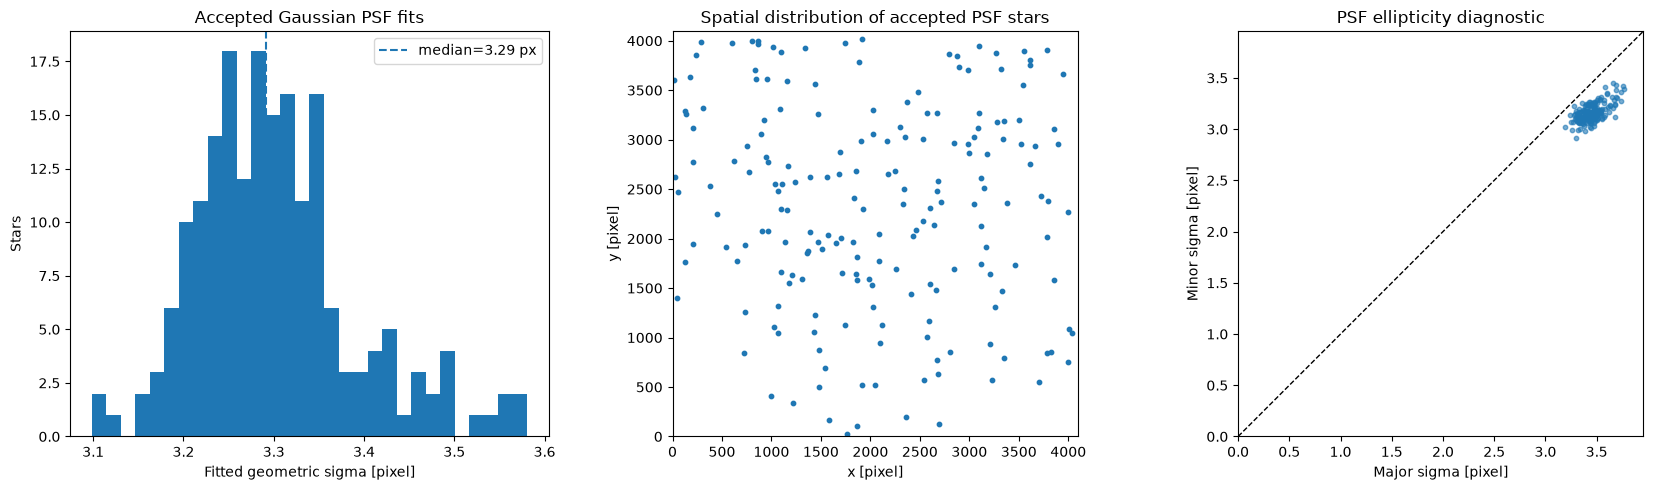

,n_stars,median_sigma_px,MAD_sigma_px
quadrant,,,
lower-left,43,3.309408,0.065132
lower-right,36,3.310733,0.060700
upper-left,57,3.297058,0.090174
upper-right,56,3.252765,0.064413


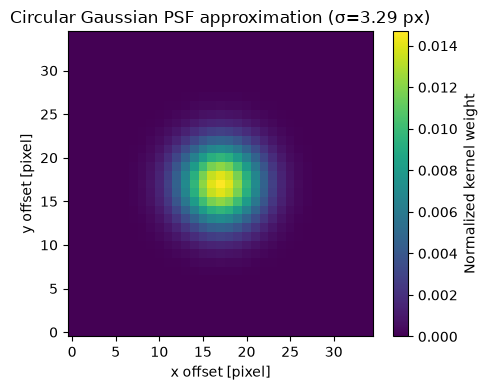

In [15]:
# Diagnostic fit-quality filter; review its effect rather than treating it as universal.
psf_accepted = (
    (psf_fit_table["peak_to_local_rms"] >= PSF_MIN_PEAK_TO_RMS) &
    np.isfinite(psf_fit_table["reduced_chi2"]) &
    (psf_fit_table["reduced_chi2"] <= PSF_MAX_REDUCED_CHI2) &
    (psf_fit_table["sigma_minor"] >= PSF_MIN_MINOR_SIGMA)
)
psf_good = psf_fit_table.loc[psf_accepted].copy()

print("Fits passing diagnostic quality cuts:", len(psf_good), "of", len(psf_fit_table))
if len(psf_good) < 20:
    warnings.warn("Fewer than 20 acceptable PSF fits; do not freeze this PSF without further inspection.")
if len(psf_good) == 0:
    raise RuntimeError("No PSF fits passed the diagnostic quality cuts.")

PSF_SIGMA_PIX = float(np.median(psf_good["sigma_geom"]))
PSF_FWHM_PIX = 2.354820045 * PSF_SIGMA_PIX
PSF_SIGMA_MAJOR_MED = float(np.median(psf_good["sigma_major"]))
PSF_SIGMA_MINOR_MED = float(np.median(psf_good["sigma_minor"]))

print(f"Median geometric PSF sigma: {PSF_SIGMA_PIX:.3f} px")
print(f"Equivalent circular-Gaussian FWHM: {PSF_FWHM_PIX:.3f} px")
print(f"Median fitted major sigma: {PSF_SIGMA_MAJOR_MED:.3f} px")
print(f"Median fitted minor sigma: {PSF_SIGMA_MINOR_MED:.3f} px")
print("Header FWHM card:", header.get("FWHM", "not present"))
print("Header IMSCALE card:", header.get("IMSCALE", "not present"))

# Conditional comparison only: valid if FWHM and IMSCALE are expressed in
# compatible angular units (e.g. arcsec and arcsec/pixel). Confirm the
# instrument keyword convention before treating this as a formal PSF check.
header_fwhm = header.get("FWHM", None)
header_scale = header.get("IMSCALE", None)
if header_fwhm is not None and header_scale is not None:
    try:
        header_fwhm_px = float(header_fwhm) / float(header_scale)
        if np.isfinite(header_fwhm_px) and header_fwhm_px > 0:
            print(f"Conditional header-derived FWHM: {header_fwhm_px:.3f} px")
            print(f"Fitted/header FWHM ratio: {PSF_FWHM_PIX / header_fwhm_px:.3f}")
    except (TypeError, ValueError, ZeroDivisionError):
        print("Header FWHM/IMSCALE could not be compared numerically.")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].hist(psf_good["sigma_geom"], bins=30)
axes[0].axvline(PSF_SIGMA_PIX, linestyle="--", label=f"median={PSF_SIGMA_PIX:.2f} px")
axes[0].set_xlabel("Fitted geometric sigma [pixel]")
axes[0].set_ylabel("Stars")
axes[0].set_title("Accepted Gaussian PSF fits")
axes[0].legend()

axes[1].scatter(psf_good["x"], psf_good["y"], s=10)
axes[1].set_xlim(0, nx-1)
axes[1].set_ylim(0, ny-1)
axes[1].set_aspect("equal")
axes[1].set_title("Spatial distribution of accepted PSF stars")
axes[1].set_xlabel("x [pixel]")
axes[1].set_ylabel("y [pixel]")

axes[2].scatter(psf_good["sigma_major"], psf_good["sigma_minor"], s=10, alpha=0.6)
lim = max(psf_good["sigma_major"].max(), psf_good["sigma_minor"].max()) * 1.05
axes[2].plot([0, lim], [0, lim], "k--", linewidth=1)
axes[2].set_xlim(0, lim)
axes[2].set_ylim(0, lim)
axes[2].set_aspect("equal")
axes[2].set_xlabel("Major sigma [pixel]")
axes[2].set_ylabel("Minor sigma [pixel]")
axes[2].set_title("PSF ellipticity diagnostic")
plt.tight_layout()
plt.show()

# Quadrant summaries
mid_x, mid_y = nx/2, ny/2
quadrant_masks = {
    "lower-left": (psf_good.x < mid_x) & (psf_good.y < mid_y),
    "lower-right": (psf_good.x >= mid_x) & (psf_good.y < mid_y),
    "upper-left": (psf_good.x < mid_x) & (psf_good.y >= mid_y),
    "upper-right": (psf_good.x >= mid_x) & (psf_good.y >= mid_y)
}
quadrant_rows=[]
for name, qmask in quadrant_masks.items():
    vals = psf_good.loc[qmask, "sigma_geom"].to_numpy()
    quadrant_rows.append({
        "quadrant": name,
        "n_stars": int(len(vals)),
        "median_sigma_px": float(np.median(vals)) if len(vals) else np.nan,
        "MAD_sigma_px": float(1.4826*np.median(np.abs(vals-np.median(vals)))) if len(vals) else np.nan
    })
psf_quadrant_table = pd.DataFrame(quadrant_rows).set_index("quadrant")
display(psf_quadrant_table)

# Normalized circular-Gaussian PSF kernel for inspection only.
k_radius = max(3, int(np.ceil(5 * PSF_SIGMA_PIX)))
ky, kx = np.mgrid[-k_radius:k_radius+1, -k_radius:k_radius+1]
psf_kernel = np.exp(-0.5 * (kx**2 + ky**2) / PSF_SIGMA_PIX**2)
psf_kernel /= psf_kernel.sum()

plt.figure(figsize=(5, 4))
plt.imshow(psf_kernel, origin="lower", cmap="viridis")
plt.colorbar(label="Normalized kernel weight")
plt.title(f"Circular Gaussian PSF approximation (σ={PSF_SIGMA_PIX:.2f} px)")
plt.xlabel("x offset [pixel]")
plt.ylabel("y offset [pixel]")
plt.tight_layout()
plt.show()

## Stage 17 — Point-source suppression diagnostic branch

Nir et al. recommend removing point sources or subtracting a suitable reference image before the FRT. Residual stars can create line-like structures in Radon space and overwhelm faint trails. Diffraction spikes, bleeding and extended halos may remain and require separate treatment.

No suitable reference image is supplied for this single-frame experiment. We therefore build a **heuristic compact-source stamp mask** from the SEP catalogue. It is an experimental alternative, not validated point-source subtraction:

- `residual_image` remains the canonical unmasked, truth-blind residual.
- `point_source_mask` marks compact, approximately round SEP detections.
- `residual_pointsource_masked` sets those stamp pixels to zero before PyRaDoN's PSF convolution. The mask boundary can itself create structure, so compare this branch with `FRT_SOURCE_MODE="unmasked"` before interpreting detections.
- `variance_pointsource_masked` records masked locations as NaN for diagnostics. The FRT branch uses the unmasked background-variance proxy, conservatively retaining noise weight in zeroed source pixels; this is not a full masked-noise likelihood.
- We measure how much of the manually annotated corridor this mask would erase. The annotation is not used to protect the trail, avoiding label leakage.

The compact mask is not equivalent to reference-image subtraction or a fitted PSF-model subtraction. Its parameters are defined in the single configuration cell. Treat it as a controlled experiment and inspect the mask overlay before using it for a full-frame search.

Compact source candidates: 1222
Point-source mask pixels: 340315
Point-source mask fraction: 0.02028435468673706
Annotated corridor masked fraction: 0.0014057507987220448


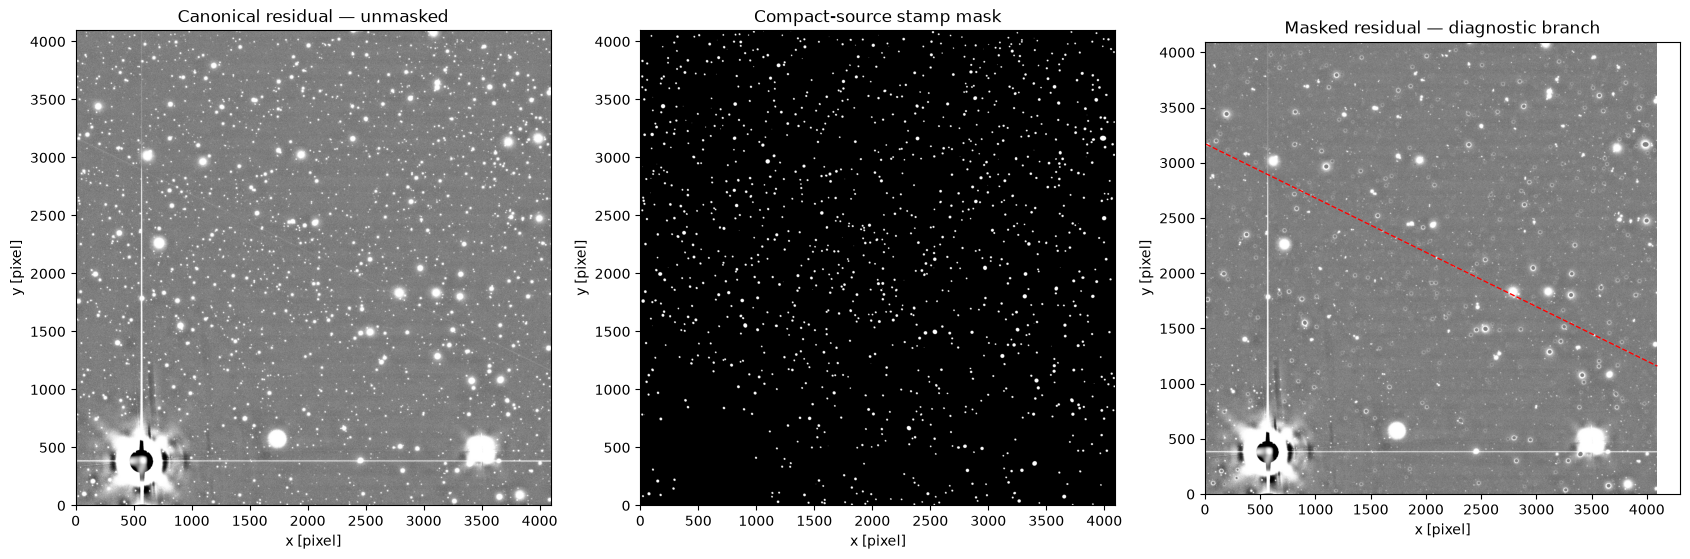

In [16]:
# Compact-source mask settings were defined in the single configuration cell.
STAR_MASK_MAX_SEMIAXIS_PIX = max(
    STAR_MASK_MIN_SEMIAXIS_PIX,
    STAR_MASK_MAX_SEMIAXIS_FACTOR * PSF_SIGMA_PIX
)

pointlike_source_mask = (
    finite_source &
    (src_flags == 0) &
    (axis_ratio >= STAR_MASK_AXIS_RATIO_MIN) &
    (src_size <= STAR_MASK_MAX_SEMIAXIS_PIX)
)
pointlike_indices = np.flatnonzero(pointlike_source_mask)
point_source_mask = np.zeros(image_raw.shape, dtype=bool)

for idx in pointlike_indices:
    x0 = float(src_x[idx])
    y0 = float(src_y[idx])
    a0 = float(src_a[idx]) * STAR_MASK_RADIUS_FACTOR
    b0 = float(src_b[idx]) * STAR_MASK_RADIUS_FACTOR
    theta0 = float(objects["theta"][idx])
    ct, st = np.cos(theta0), np.sin(theta0)

    # Bounding box of the rotated ellipse.
    rx = np.sqrt((a0 * ct)**2 + (b0 * st)**2)
    ry = np.sqrt((a0 * st)**2 + (b0 * ct)**2)
    xlo = max(0, int(np.floor(x0 - rx - 1)))
    xhi = min(nx, int(np.ceil(x0 + rx + 2)))
    ylo = max(0, int(np.floor(y0 - ry - 1)))
    yhi = min(ny, int(np.ceil(y0 + ry + 2)))
    if xlo >= xhi or ylo >= yhi:
        continue

    gy, gx = np.mgrid[ylo:yhi, xlo:xhi]
    dx, dy = gx - x0, gy - y0
    xr = ct * dx + st * dy
    yr = -st * dx + ct * dy
    ellipse = (xr / a0)**2 + (yr / b0)**2 <= 1.0
    point_source_mask[ylo:yhi, xlo:xhi] |= ellipse

point_source_mask &= valid_mask
residual_pointsource_masked = residual_image.copy()
residual_pointsource_masked[point_source_mask] = 0.0
# Masked pixels are undefined in this diagnostic branch. Keep them NaN and
# preserve point_source_mask separately; never encode masked variance as zero.
variance_pointsource_masked = variance_background_proxy.copy()
variance_pointsource_masked[point_source_mask] = np.nan

masked_trail_pixels = int((point_source_mask & annotation_mask).sum())
trail_masked_fraction = masked_trail_pixels / max(int(annotation_mask.sum()), 1)
print("Compact source candidates:", len(pointlike_indices))
print("Point-source mask pixels:", int(point_source_mask.sum()))
print("Point-source mask fraction:", float(point_source_mask.mean()))
print("Annotated corridor masked fraction:", float(trail_masked_fraction))

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
scale = RESIDUAL_DISPLAY_RMS_MULTIPLIER * float(np.nanmedian(rms_map))
axes[0].imshow(residual_image, origin="lower", cmap="gray", vmin=-scale, vmax=scale)
axes[0].set_title("Canonical residual — unmasked")
axes[1].imshow(point_source_mask, origin="lower", cmap="gray")
axes[1].set_title("Compact-source stamp mask")
axes[2].imshow(residual_pointsource_masked, origin="lower", cmap="gray", vmin=-scale, vmax=scale)
axes[2].plot(centerline[:, 0], centerline[:, 1], "r--", linewidth=1.0)
axes[2].set_title("Masked residual — diagnostic branch")
for ax in axes:
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")
plt.tight_layout()
plt.show()

if trail_masked_fraction > MASK_OVERLAP_WARNING_FRACTION:
    warnings.warn(
        "The point-source mask overlaps >10% of the manual trail corridor. "
        "Do not select this branch by default without evaluating signal loss."
    )

## Stage 18 — Validate canonical masks and noise products

This section validates arrays created once in their owning stages; it does not recreate them. Keep the meanings distinct:

- `valid_mask`: finite pixels in the original FITS array.
- `analysis_valid_mask`: finite pixels with a valid positive empirical RMS estimate.
- `annotation_mask`: manual trail corridor, used for QA and excluding the labelled line from the PSF-star catalogue.
- `psf_source_mask`: pixels masked only during PSF-star source extraction.
- `point_source_mask`: separate, optional compact-source diagnostic mask.

The canonical `residual_image` and `variance_background_proxy` remain unmasked by the compact-source diagnostic. In `variance_pointsource_masked`, masked pixels are `NaN`, not zero: zero variance could be misinterpreted as zero noise and artificially high significance. The mask must be handled explicitly by any later detector.

`variance_background_proxy = rms_map**2` is an empirical background-variance proxy. It excludes source Poisson noise and unmodelled covariance from prior processing; no detector-calibrated total variance is claimed.


In [17]:
# Validate the canonical masks and noise products created earlier.
required_products = {
    "valid_mask": valid_mask,
    "analysis_valid_mask": analysis_valid_mask,
    "annotation_mask": annotation_mask,
    "psf_source_mask": psf_source_mask,
    "variance_background_proxy": variance_background_proxy,
    "point_source_mask": point_source_mask,
}

for name, array in required_products.items():
    if array.shape != image_raw.shape:
        raise ValueError(f"{name} has shape {array.shape}; expected {image_raw.shape}.")

assert np.isfinite(residual_image[analysis_valid_mask]).all()
assert np.isfinite(variance_background_proxy[analysis_valid_mask]).all()
assert np.all(variance_background_proxy[analysis_valid_mask] > 0)
assert not np.any(annotation_mask & ~valid_mask)

print("Canonical preprocessing products validated:")
for name, array in required_products.items():
    if array.dtype == bool:
        count = int(array.sum())
        label = "true pixels"
    else:
        count = int(np.isfinite(array).sum())
        label = "finite pixels"
    print(f"{name:28s}: {count:>10,d} {label}")

print("Invalid variance-proxy pixels:", int((~np.isfinite(variance_background_proxy)).sum()))
print("Empirical variance-proxy median:", float(np.nanmedian(variance_background_proxy)))
print("GAIN header:", header.get("GAIN", header.get("DETGAIN", None)))
print("RDNOISE header:", header.get("RDNOISE", header.get("READNOISE", None)))
print("Noise-model status: empirical background variance proxy; total detector variance is not calibrated.")


Canonical preprocessing products validated:
valid_mask                  : 16,777,216 true pixels
analysis_valid_mask         : 16,776,468 true pixels
annotation_mask             :     39,125 true pixels
psf_source_mask             :     39,873 true pixels
variance_background_proxy   : 16,776,468 finite pixels
point_source_mask           :    340,315 true pixels
Invalid variance-proxy pixels: 748
Empirical variance-proxy median: 309.06390380859375
GAIN header: None
RDNOISE header: None
Noise-model status: empirical background variance proxy; total detector variance is not calibrated.


## Stage 19 — DS9-style smoothing as a display-only diagnostic

The user observed that the faint feature becomes more visible after `Analysis → Smooth` in DS9. This is useful for human inspection, but the exact DS9 kernel/radius has not been recorded. Here we show a Gaussian-smoothed residual using the measured PSF sigma as an **illustrative diagnostic only**.

Do not feed `residual_smoothed_display` into the detection stage or measure flux/width from it. Smoothing changes the effective PSF and correlates neighbouring pixels. The proper matched-filter stage will convolve with a model template and normalize using the corresponding variance treatment.

In [ ]:
smooth_weight = gaussian_filter(
    analysis_valid_mask.astype(np.float32),
    sigma=PSF_SIGMA_PIX,
    mode="reflect"
)
smooth_numerator = gaussian_filter(
    np.where(analysis_valid_mask, residual_image, 0.0).astype(np.float32),
    sigma=PSF_SIGMA_PIX,
    mode="reflect"
)
residual_smoothed_display = np.divide(
    smooth_numerator,
    smooth_weight,
    out=np.full_like(smooth_numerator, np.nan),
    where=smooth_weight > 1e-6
)

resid_display_scale = RESIDUAL_DISPLAY_RMS_MULTIPLIER * float(np.nanmedian(rms_map))
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
axes[0].imshow(
    residual_image, origin="lower", cmap="gray",
    vmin=-resid_display_scale, vmax=resid_display_scale,
    interpolation="nearest"
)
axes[0].set_title("Unfiltered background-subtracted residual")
axes[1].imshow(
    residual_smoothed_display, origin="lower", cmap="gray",
    vmin=-resid_display_scale, vmax=resid_display_scale,
    interpolation="nearest"
)
axes[1].set_title("Gaussian-smoothed display diagnostic")
axes[2].imshow(
    rms_map, origin="lower", cmap="gray",
    vmin=np.nanpercentile(rms_map, 1),
    vmax=np.nanpercentile(rms_map, 99),
    interpolation="nearest"
)
axes[2].set_title("Empirical local RMS map")
for ax in axes:
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")
plt.tight_layout()
plt.show()

## Stage 20 — Consolidated preprocessing visualization

This final figure gathers the canonical products that will feed the next detection stage. The original image, background-subtracted residual, RMS map, annotation, source catalogue and PSF model remain separately identifiable.

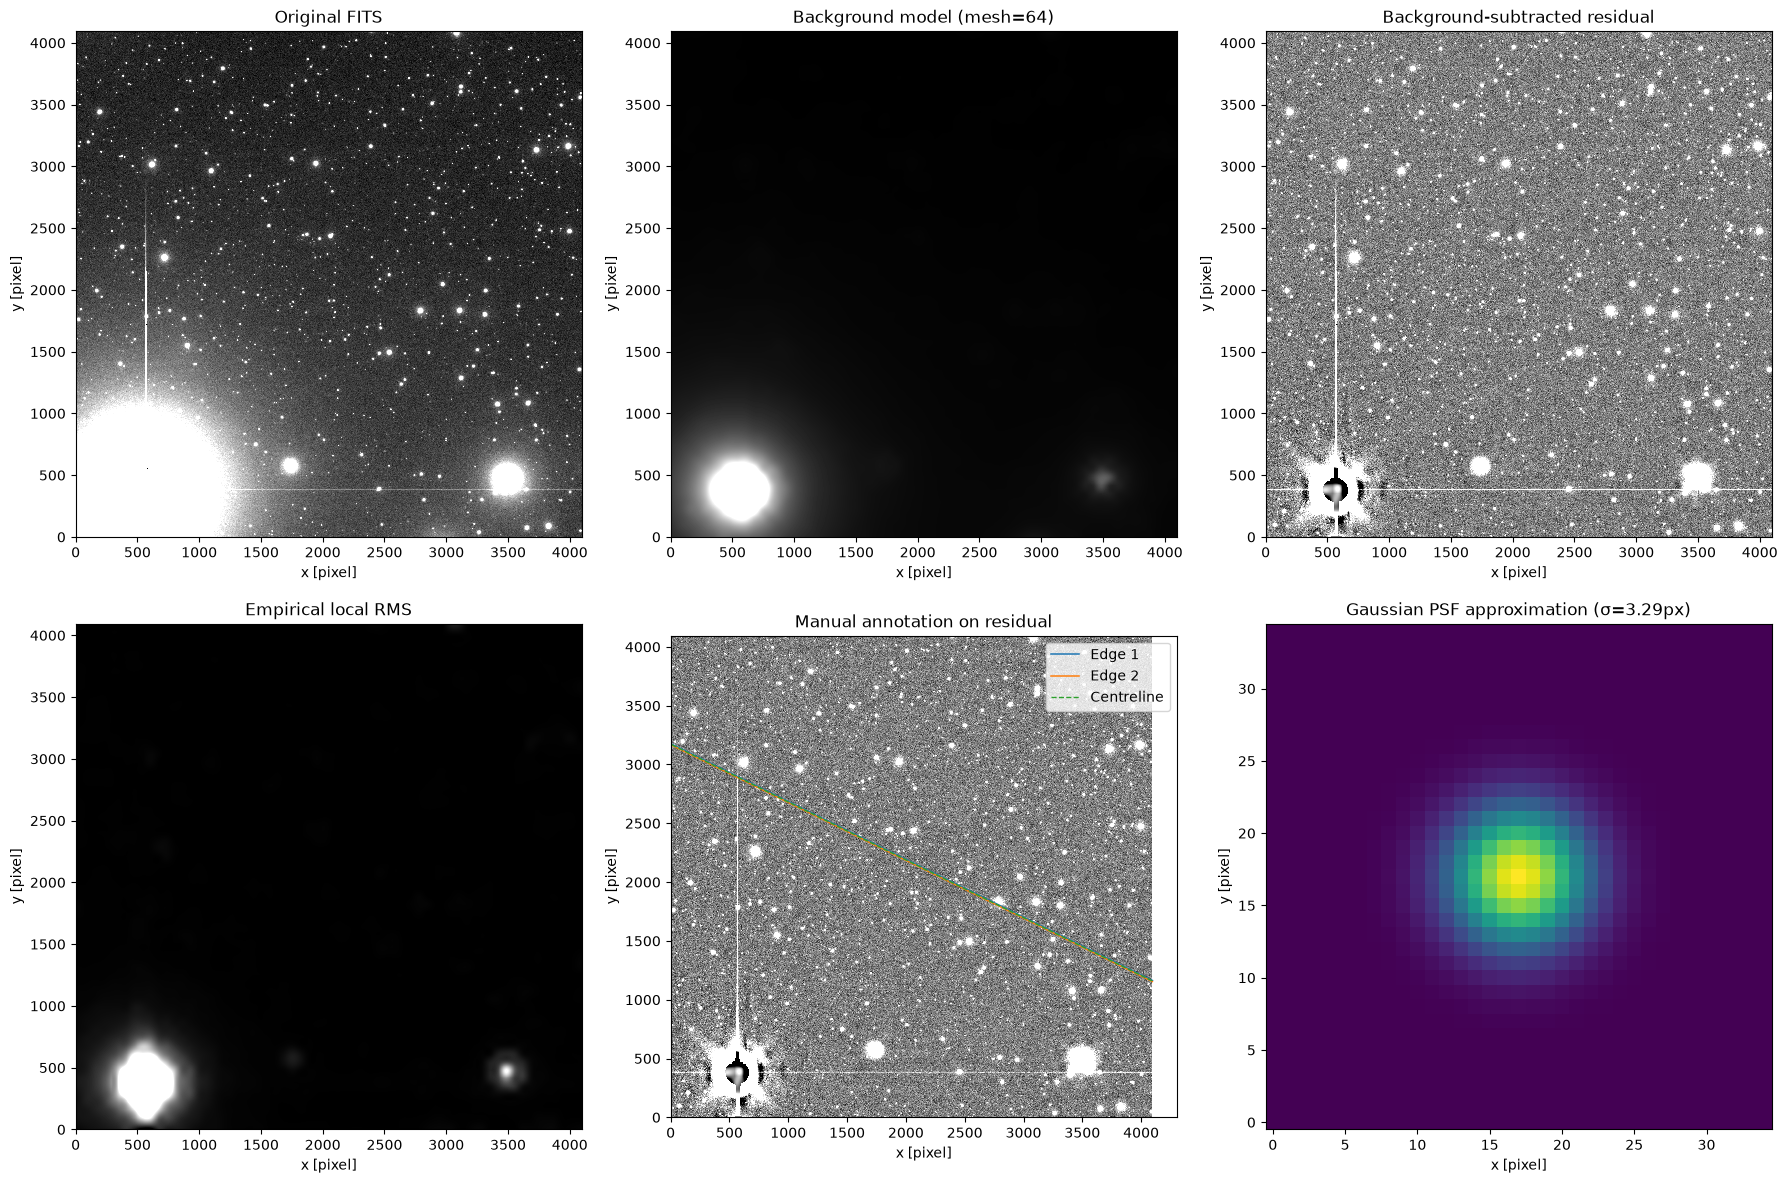

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes[0, 0].imshow(
    image_raw, origin="lower", cmap="gray",
    vmin=display_vmin, vmax=display_vmax,
    interpolation="nearest"
)
axes[0, 0].set_title("Original FITS")

axes[0, 1].imshow(
    background_map, origin="lower", cmap="gray",
    vmin=np.nanpercentile(background_map, 1),
    vmax=np.nanpercentile(background_map, 99),
    interpolation="nearest"
)
axes[0, 1].set_title(f"Background model (mesh={BG_MESH_SIZE})")

scale = RESIDUAL_DISPLAY_RMS_MULTIPLIER * float(np.nanmedian(rms_map))
axes[0, 2].imshow(
    residual_image, origin="lower", cmap="gray",
    vmin=-scale, vmax=scale,
    interpolation="nearest"
)
axes[0, 2].set_title("Background-subtracted residual")

axes[1, 0].imshow(
    rms_map, origin="lower", cmap="gray",
    vmin=np.nanpercentile(rms_map, 1),
    vmax=np.nanpercentile(rms_map, 99),
    interpolation="nearest"
)
axes[1, 0].set_title("Empirical local RMS")

axes[1, 1].imshow(
    residual_image, origin="lower", cmap="gray",
    vmin=-scale, vmax=scale,
    interpolation="nearest"
)
axes[1, 1].plot(edge_pixels[0, :, 0], edge_pixels[0, :, 1], linewidth=1.1, label="Edge 1")
axes[1, 1].plot(edge_pixels[1, :, 0], edge_pixels[1, :, 1], linewidth=1.1, label="Edge 2")
axes[1, 1].plot(centerline[:, 0], centerline[:, 1], "--", linewidth=1.0, label="Centreline")
axes[1, 1].set_title("Manual annotation on residual")
axes[1, 1].legend(loc="best")

axes[1, 2].imshow(psf_kernel, origin="lower", cmap="viridis")
axes[1, 2].set_title(f"Gaussian PSF approximation (σ={PSF_SIGMA_PIX:.2f}px)")

for ax in axes.flat:
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")
plt.tight_layout()
plt.show()

## Stage 21 — Export reproducible preprocessing products

The notebook saves:

- the background mesh comparison table;
- the successful PSF-fit catalogue and quadrant summary;
- a JSON run manifest with file identity, software versions and selected parameters;
- optionally, a compressed NPZ containing the canonical arrays and masks.

The NPZ does not include a detection result. `residual_smoothed_display` is stored under a diagnostic name so it cannot be mistaken for the quantitative detector input.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

background_comparison.to_csv(OUTPUT_DIR / "background_mesh_comparison.csv")
psf_fit_table.to_csv(OUTPUT_DIR / "psf_fits_all.csv", index=False)
psf_good.to_csv(OUTPUT_DIR / "psf_fits_accepted.csv", index=False)
psf_quadrant_table.to_csv(OUTPUT_DIR / "psf_quadrant_summary.csv")

run_manifest = {
    "frame_filename": FRAME_PATH.name,
    "frame_path": str(FRAME_PATH.resolve()),
    "sha256": actual_sha256,
    "date_obs": observed_date,
    "shape": list(image_raw.shape),
    "dtype": str(image_raw.dtype),
    "median": image_median,
    "robust_global_sigma": image_mad_sigma,
    "finite_fraction": float(valid_mask.mean()),
    "edge_region_path": str(EDGE_REGION_PATH.resolve()),
    "edge_region_coordinate_system": "DS9 IMAGE",
    "edge_lengths_px": [float(v) for v in edge_lengths],
    "annotation_width_endpoints_px": [float(v) for v in width_at_endpoints],
    "annotation_mask_pixels": annotation_pixel_count,
    "point_source_mask_pixels": int(point_source_mask.sum()),
    "point_source_mask_fraction": float(point_source_mask.mean()),
    "annotated_corridor_masked_fraction": float(trail_masked_fraction),
    "background_mesh_options": list(BG_MESH_OPTIONS),
    "selected_background_mesh": int(BG_MESH_SIZE),
    "background_rms_median": float(np.nanmedian(rms_map)),
    "variance_model": "empirical local background RMS squared; not calibrated total detector variance",
    "psf_fits_attempted": int(len(fit_indices)),
    "psf_fits_successful": int(len(psf_fit_table)),
    "psf_fits_accepted": int(len(psf_good)),
    "psf_sigma_median_px": PSF_SIGMA_PIX,
    "psf_fwhm_equivalent_px": PSF_FWHM_PIX,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "astropy_version": astropy.__version__,
    "sep_version": str(getattr(sep, "__version__", "unknown")),
    "scipy_version": scipy.__version__
}

with open(OUTPUT_DIR / "preprocessing_manifest.json", "w", encoding="utf-8") as handle:
    json.dump(run_manifest, handle, indent=2)

if EXPORT_ARRAYS:
    np.savez_compressed(
        OUTPUT_DIR / "preprocessing_arrays.npz",
        image_raw=image_raw.astype(np.float32),
        background_map=background_map.astype(np.float32),
        residual_image=residual_image.astype(np.float32),
        rms_map=rms_map.astype(np.float32),
        variance_background_proxy=variance_background_proxy.astype(np.float32),
        valid_mask=valid_mask.astype(np.uint8),
        analysis_valid_mask=analysis_valid_mask.astype(np.uint8),
        annotation_mask=annotation_mask.astype(np.uint8),
        point_source_mask=point_source_mask.astype(np.uint8),
        residual_pointsource_masked=residual_pointsource_masked.astype(np.float32),
        variance_pointsource_masked=variance_pointsource_masked.astype(np.float32),
        residual_smoothed_display=residual_smoothed_display.astype(np.float32),
        psf_kernel=psf_kernel.astype(np.float32)
    )

print("Exported preprocessing products to:", OUTPUT_DIR.resolve())
print("Input SHA-256:", actual_sha256)


Exported preprocessing products to: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/preprocessing/20221026-0057
Input SHA-256: 49d29e18f54b729456bd166f7037e551c727d7a32e8cde5530a776527bd38a10


## Stage 22 — Final preprocessing acceptance report

This is the formal stopping point for this notebook. It does not declare streak-detection performance. It records whether the input data and preprocessing products are suitable for a controlled FRT/matched-filter experiment.

Before proceeding, manually confirm the annotation overlay and crop panels. If the ground truth is wrong, no detector metric based on it is meaningful.

In [ ]:
checks = {
    "exact_target_filename": FRAME_PATH.name == FRAME_FILENAME,
    "expected_observation_date": observed_date == EXPECTED_DATE_OBS,
    "expected_shape": image_raw.shape == EXPECTED_SHAPE,
    "all_image_pixels_finite": bool(valid_mask.all()),
    "annotation_nonempty": annotation_pixel_count > 0,
    "annotation_width_positive": bool(np.all(width_at_endpoints > 0)),
    "point_source_mask_created": bool(point_source_mask.shape == image_raw.shape),
    "point_source_masked_variance_not_zero": bool(np.all(~np.isfinite(variance_pointsource_masked[point_source_mask]))),
    "background_map_finite_on_valid_pixels": bool(np.isfinite(background_map[valid_mask]).mean() > 0.999),
    "rms_positive_on_analysis_pixels": bool(np.all(rms_map[analysis_valid_mask] > 0)),
    "variance_proxy_positive": bool(np.all(variance_background_proxy[analysis_valid_mask] > 0)),
    "psf_accepted_fits_at_least_20": len(psf_good) >= 20
}

acceptance_table = pd.DataFrame({"check": list(checks.keys()), "passed": list(checks.values())})
display(acceptance_table)

print("\nPREPROCESSING SUMMARY")
print("---------------------")
print("Frame:", FRAME_PATH.name)
print("DATE-OBS:", observed_date)
print("Background mesh:", BG_MESH_SIZE, "(reviewed manually against alternatives)")
print("Median empirical RMS:", float(np.nanmedian(rms_map)))
print("PSF sigma:", PSF_SIGMA_PIX, "px")
print("PSF FWHM equivalent:", PSF_FWHM_PIX, "px")
print("Manual annotation width:", float(width_at_endpoints.mean()), "px")
print("Output directory:", OUTPUT_DIR.resolve())

if not all(checks.values()):
    warnings.warn(
        "One or more preprocessing acceptance checks failed. "
        "Do not proceed to FRT until the failed checks are resolved."
    )
else:
    print("Automated checks passed. Human visual acceptance of annotation/background/PSF is still required.")

,check,passed
0,exact_target_filename,True
1,expected_observation_date,True
2,expected_shape,True
3,all_image_pixels_finite,True
4,annotation_nonempty,True
5,annotation_width_positive,True
6,point_source_mask_created,True
7,point_source_masked_variance_not_zero,True
8,background_map_finite_on_valid_pixels,True
9,rms_positive_on_analysis_pixels,True



PREPROCESSING SUMMARY
---------------------
Frame: 20221026-0057.fits
DATE-OBS: 2022-10-26
Background mesh: 64 (reviewed manually against alternatives)
Median empirical RMS: 17.58021354675293
PSF sigma: 3.2912910531342403 px
PSF FWHM equivalent: 7.750398145849669 px
Manual annotation width: 8.594816450727667 px
Output directory: /home/deepmalya/pip_malya/ILMT_Streak_Detection/outputs/preprocessing/20221026-0057
Automated checks passed. Human visual acceptance of annotation/background/PSF is still required.


```mermaid
graph TD
    A[Original FITS] --> B[Background Subtraction]
    B --> C[Local Variance Estimate]
    C --> D[Empirical PSF Estimate]
    D --> E[PSF-Matched Filtering]
    E --> F[Fast Radon Transform]
    F --> G[Multiple Candidate Extraction]
    G --> H[Candidate Clustering]
    H --> I[Endpoint & Width Refinement]
    I --> J[Flux & S/N Characterization]
    J --> K[Physical Classification]

    style A fill:#f9f,stroke:#333,stroke-width:2px
    style K fill:#bbf,stroke:#333,stroke-width:2px
```


## Stage 23 — Prepare the long-streak FRT experiment

This stage prepares the canonical image and variance arrays, checks the preprocessing manifest, fingerprints the exact FRT inputs, verifies the local PyRaDoN checkout, and runs a small compatibility smoke test before any full-frame search.

The intended configuration uses **long/full-length mode** (`FRT_USE_SHORT=False`) for the corner-crossing target. The pinned PyRaDoN long-mode implementation needs guarded compatibility handling: its PSF normalization must be called, its 3-D geometric factor must be reduced to match the 2-D Radon map, the maximum selection must tolerate NaNs, and the flattened peak index must produce a scalar. The notebook applies these fixes in memory where needed, then exercises the long-mode path on a small zero image.

The full-frame search remains opt-in because expansion can require substantial memory. The compact-source mask is heuristic and is not a validated substitute for reference-image or PSF-model subtraction.

In [ ]:
# ============================================================
# STAGE 23 — PREPARE A REPRODUCIBLE LONG-STREAK FRT EXPERIMENT
# ============================================================

# Use the canonical preprocessing arrays already created above.
PREPROCESS_JSON = OUTPUT_DIR / "preprocessing_manifest.json"
if not PREPROCESS_JSON.is_file():
    raise FileNotFoundError(
        "Preprocessing manifest is missing. Execute the preprocessing/export stage first."
    )
with open(PREPROCESS_JSON, "r", encoding="utf-8") as handle:
    preprocessing_manifest = json.load(handle)
if preprocessing_manifest.get("sha256") != actual_sha256:
    raise RuntimeError("Preprocessing manifest SHA-256 does not match the loaded FITS file.")
if tuple(preprocessing_manifest.get("shape", [])) != tuple(image_raw.shape):
    raise RuntimeError("Preprocessing manifest image shape does not match the live image.")

manifest_psf_sigma = float(preprocessing_manifest["psf_sigma_median_px"])
manifest_psf_fwhm = float(preprocessing_manifest["psf_fwhm_equivalent_px"])
if not np.isfinite(PSF_SIGMA_PIX) or PSF_SIGMA_PIX <= 0:
    raise ValueError(f"Invalid live PSF sigma: {PSF_SIGMA_PIX}")
if not np.isclose(manifest_psf_sigma, PSF_SIGMA_PIX, rtol=1e-8, atol=1e-10):
    raise RuntimeError("PSF sigma in the manifest differs from the live preprocessing result.")
if not np.isclose(manifest_psf_fwhm, PSF_FWHM_PIX, rtol=1e-8, atol=1e-10):
    raise RuntimeError("PSF FWHM in the manifest differs from the live preprocessing result.")

if FRT_SOURCE_MODE == "compact_mask":
    retained_trail_fraction = 1.0 - float(trail_masked_fraction)
    if retained_trail_fraction < (1.0 - MASK_OVERLAP_WARNING_FRACTION):
        raise RuntimeError(
            "Compact-source mask overlaps too much of the manual trail corridor; "
            "inspect mask/annotation before using this FRT branch."
        )
    selected_residual = residual_pointsource_masked.copy()
elif FRT_SOURCE_MODE == "unmasked":
    selected_residual = residual_image.copy()
else:
    raise ValueError("FRT_SOURCE_MODE must be 'compact_mask' or 'unmasked'.")

frt_image_input = np.asarray(selected_residual, dtype=np.float32).copy()
invalid_image_pixels = (~analysis_valid_mask) | (~np.isfinite(frt_image_input))
frt_image_input[invalid_image_pixels] = 0.0

frt_variance_input = np.asarray(variance_background_proxy, dtype=np.float32).copy()
bad_variance_mask = (~np.isfinite(frt_variance_input)) | (frt_variance_input <= 0)
variance_fill_count = int(bad_variance_mask.sum())
if variance_fill_count:
    if not (~bad_variance_mask).any():
        raise RuntimeError("No valid pixels remain in the variance proxy.")
    nearest_indices = distance_transform_edt(
        bad_variance_mask, return_distances=False, return_indices=True
    )
    frt_variance_input[bad_variance_mask] = frt_variance_input[
        tuple(nearest_indices[:, bad_variance_mask])
    ]

frt_image_input = np.ascontiguousarray(frt_image_input, dtype=np.float32)
frt_variance_input = np.ascontiguousarray(frt_variance_input, dtype=np.float32)
if not np.isfinite(frt_image_input).all():
    raise RuntimeError("FRT input image still contains non-finite pixels.")
if not np.isfinite(frt_variance_input).all() or np.any(frt_variance_input <= 0):
    raise RuntimeError("FRT variance input must be finite and strictly positive.")
frt_sigma_map = np.sqrt(frt_variance_input)

_frt_input_hasher = hashlib.sha256()
_frt_input_hasher.update(np.asarray(frt_image_input.shape, dtype=np.int64).tobytes())
_frt_input_hasher.update(memoryview(frt_image_input).cast("B"))
_frt_input_hasher.update(memoryview(frt_variance_input).cast("B"))
FRT_INPUT_SHA256 = _frt_input_hasher.hexdigest()
del _frt_input_hasher

print("FRT input summary")
print("-----------------")
print("Frame:", FRAME_FILENAME)
print("Shape:", frt_image_input.shape)
print("PSF sigma [px]:", PSF_SIGMA_PIX)
print("Source mode:", FRT_SOURCE_MODE)
print("Invalid residual pixels neutralized:", int(invalid_image_pixels.sum()))
print("Variance pixels nearest-valid filled:", variance_fill_count)
print("Variance model: empirical SEP background RMS squared; not calibrated total detector variance")

if not (PYRADON_ROOT / "src" / "finder.py").is_file():
    raise FileNotFoundError(
        f"PyRaDoN source not found at {PYRADON_ROOT}. "
        "Clone/install the reference repository at the configured path."
    )
for import_path in (PYRADON_ROOT, PYRADON_ROOT / "src"):
    if str(import_path) not in sys.path:
        sys.path.insert(0, str(import_path))

from src.finder import Finder
from streak import model as pyradon_streak_model

try:
    PYRADON_COMMIT = subprocess.check_output(
        ["git", "-C", str(PYRADON_ROOT), "rev-parse", "HEAD"],
        text=True,
        stderr=subprocess.DEVNULL,
    ).strip()
except Exception:
    PYRADON_COMMIT = "unavailable (source directory is not a Git checkout)"

PYRADON_SOURCE_ROOT = PYRADON_ROOT / "src"
PYRADON_SOURCE_FILES = sorted(PYRADON_SOURCE_ROOT.rglob("*.py"))
if not PYRADON_SOURCE_FILES:
    raise FileNotFoundError(f"No Python source files found under {PYRADON_SOURCE_ROOT}.")
_pyradon_hasher = hashlib.sha256()
for source_file in PYRADON_SOURCE_FILES:
    _pyradon_hasher.update(source_file.relative_to(PYRADON_ROOT).as_posix().encode("utf-8"))
    _pyradon_hasher.update(b"\0")
    with open(source_file, "rb") as source_handle:
        for source_block in iter(lambda: source_handle.read(1024 * 1024), b""):
            _pyradon_hasher.update(source_block)
PYRADON_SOURCE_SHA256 = _pyradon_hasher.hexdigest()
del _pyradon_hasher

# Fix the pinned long-mode defects only in memory. In particular, the Radon
# map and variance are 2-D, while get_geometric_factor() returns (slopes,1,1).
def patch_pyradon_long_mode(finder_class):
    source = textwrap.dedent(inspect.getsource(finder_class.find_single))
    changes = []

    substitutions = (
        (
            re.compile(r"(?m)^(\s*)psf_factor\s*=\s*self\.get_norm_factor_psf\s*$"),
            r"\1psf_factor = self.get_norm_factor_psf()",
            "called get_norm_factor_psf()",
        ),
        (
            re.compile(r"(?m)^(\s*)geom_factor\s*=\s*self\.get_geometric_factor\(foldings\)\s*$"),
            r"\1geom_factor = self.get_geometric_factor(foldings)[:, 0, :]",
            "reshaped geometric factor to (n_slopes, 1)",
        ),
        (
            re.compile(r"(?m)^(\s*)best_snr\s*=\s*radon_image\[idx\]\s*$"),
            r"\1best_snr = float(radon_image.flat[idx])",
            "extracted flattened Radon peak as a scalar",
        ),
    )
    for pattern, replacement, description in substitutions:
        if pattern.search(source):
            source, count = pattern.subn(replacement, source, count=1)
            if count != 1:
                raise RuntimeError(f"Could not apply PyRaDoN fix: {description}.")
            changes.append(description)

    bad_argmax = re.compile(r"(?m)^(\s*)idx\s*=\s*np\.argmax\(radon_image\)\s*$")
    if bad_argmax.search(source):
        def replace_argmax(match):
            indent = match.group(1)
            return (
                indent + "if not np.isfinite(radon_image).any():\n" +
                indent + "    return None\n" +
                indent + "idx = np.nanargmax(radon_image)"
            )
        source, count = bad_argmax.subn(replace_argmax, source, count=1)
        if count != 1:
            raise RuntimeError("Could not apply PyRaDoN NaN-safe Radon maximum fix.")
        changes.append("used finite-aware Radon maximum selection")

    required_lines = (
        "psf_factor = self.get_norm_factor_psf()",
        "geom_factor = self.get_geometric_factor(foldings)[:, 0, :]",
        "best_snr = float(radon_image.flat[idx])",
        "idx = np.nanargmax(radon_image)",
    )
    missing = [line for line in required_lines if line not in source]
    if missing:
        raise RuntimeError(f"PyRaDoN long-mode source is unrecognized; missing statements: {missing}")

    if changes:
        namespace = dict(finder_class.find_single.__globals__)
        exec(compile(source, inspect.getsourcefile(finder_class), "exec"), namespace)
        finder_class.find_single = namespace["find_single"]
        return "applied in-memory fixes: " + "; ".join(changes)
    return "all verified long-mode statements already corrected"

PATCH_STATUS = patch_pyradon_long_mode(Finder)
print("PyRaDoN commit:", PYRADON_COMMIT)
print("Long-mode patch:", PATCH_STATUS)

# Smoke-test the exact long-mode branch on a small zero image before proceeding.
smoke_finder = Finder(
    threshold=1e9,
    num_iterations=1,
    min_length=FRT_MIN_LENGTH_PIX,
    use_short=False,
    use_sections=False,
    use_exclude=False,
    use_subtract_mean=False,
    use_conv=True,
    verbosity=0,
)
smoke_image = np.zeros((128, 128), dtype=np.float32)
smoke_finder.data.image = smoke_image
smoke_finder.data.variance = np.ones_like(smoke_image)
smoke_finder.data.psf = float(PSF_SIGMA_PIX)
smoke_finder.data._current_section_corner = (0, 0)
smoke_result = smoke_finder.find_single(smoke_image, transpose=False, threshold=1e9)
if smoke_result is not None:
    raise RuntimeError("Unexpected candidate in the zero-image PyRaDoN smoke test.")
smoke_radon = smoke_finder.data.radon_image
if smoke_radon is None or smoke_radon.ndim != 2 or not np.isfinite(smoke_radon).any():
    raise RuntimeError("PyRaDoN long-mode smoke test did not produce a finite 2-D Radon map.")
print("PASS: PyRaDoN long-mode smoke test; Radon map shape:", smoke_radon.shape)
smoke_finder.data.clear_radon_var_cache()
smoke_finder.data.radon_image = None
del smoke_finder, smoke_image, smoke_result, smoke_radon
gc.collect()

finder = Finder(
    threshold=FRT_MIN_THRESHOLD,
    num_iterations=FRT_NUM_ITERATIONS,
    min_length=FRT_MIN_LENGTH_PIX,
    use_short=FRT_USE_SHORT,
    use_sections=FRT_USE_SECTIONS,
    use_exclude=FRT_USE_EXCLUDE,
    use_subtract_mean=FRT_USE_SUBTRACT_MEAN,
    use_conv=True,
    verbosity=0,
)
finder.data.image = frt_image_input
finder.data.variance = frt_variance_input
finder.data.psf = float(PSF_SIGMA_PIX)
finder.data.filename = FRAME_FILENAME
finder.data._current_section_corner = (0, 0)

initial_work_image = np.asarray(finder.preprocess(frt_image_input.copy()), dtype=np.float32)
if initial_work_image.shape != frt_image_input.shape or not np.isfinite(initial_work_image).all():
    raise RuntimeError("PyRaDoN preprocessing returned an invalid image.")
max_pointwise_snr = float(np.nanmax(initial_work_image / frt_sigma_map))
if not np.isfinite(max_pointwise_snr):
    raise RuntimeError("Could not calculate finite maximum pointwise S/N.")
if max_pointwise_snr <= FRT_MIN_THRESHOLD:
    FRT_THRESHOLDS = np.asarray([], dtype=float)
else:
    dynamic_range = np.log2(max_pointwise_snr / FRT_MIN_THRESHOLD)
    FRT_THRESHOLDS = np.flip(
        FRT_MIN_THRESHOLD * 2 ** np.arange(dynamic_range + 1)
    ).astype(float)

FRT_RUN_DIR = OUTPUT_DIR / FRT_RUN_TAG
FRT_RUN_DIR.mkdir(parents=True, exist_ok=True)
WORK_IMAGE_INITIAL_PATH = FRT_RUN_DIR / "working_image_initial.npy"

def atomic_save_npy(path, array):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    with open(temporary, "wb") as handle:
        np.save(handle, np.asarray(array), allow_pickle=False)
    os.replace(temporary, path)

atomic_save_npy(WORK_IMAGE_INITIAL_PATH, initial_work_image)
FRT_RUN_SIGNATURE = {
    "frame": FRAME_FILENAME,
    "sha256": actual_sha256,
    "frt_input_sha256": FRT_INPUT_SHA256,
    "pyradon_commit": PYRADON_COMMIT,
    "pyradon_source_sha256": PYRADON_SOURCE_SHA256,
    "pyradon_runtime_patch": PATCH_STATUS,
    "image_shape": list(frt_image_input.shape),
    "psf_sigma_pix": float(PSF_SIGMA_PIX),
    "variance_model": "empirical background RMS squared; not calibrated total detector variance",
    "source_mode": FRT_SOURCE_MODE,
    "thresholds": FRT_THRESHOLDS.tolist(),
    "num_iterations": int(FRT_NUM_ITERATIONS),
    "min_length_pix": int(FRT_MIN_LENGTH_PIX),
    "use_short": bool(FRT_USE_SHORT),
    "use_expand": bool(not FRT_USE_SHORT),
    "use_exclude": bool(FRT_USE_EXCLUDE),
    "use_sections": bool(FRT_USE_SECTIONS),
    "use_subtract_mean": bool(FRT_USE_SUBTRACT_MEAN),
    "subtraction_model": "upstream PyRaDoN streak model; chunked local evaluation",
    "chunk_length_pix": int(FRT_CHUNK_LENGTH_PIX),
    "oversample": int(FRT_OVERSAMPLE),
    "model_threshold": float(FRT_MODEL_THRESHOLD),
}
signature_path = FRT_RUN_DIR / "run_signature.json"
if RUN_FRT:
    if signature_path.exists():
        previous_signature = json.loads(signature_path.read_text(encoding="utf-8"))
        if previous_signature != FRT_RUN_SIGNATURE:
            raise RuntimeError(
                "Existing FRT run directory has different inputs or parameters. "
                "Change FRT_RUN_TAG rather than mixing checkpoints."
            )
    else:
        signature_path.write_text(json.dumps(FRT_RUN_SIGNATURE, indent=2), encoding="utf-8")
else:
    print("RUN_FRT=False: checkpoint signature will be enforced only when the search is enabled.")

print("Threshold count:", len(FRT_THRESHOLDS))
print("Thresholds:", FRT_THRESHOLDS)
print("Short mode:", FRT_USE_SHORT)
print("RUN_FRT:", RUN_FRT)
print("Run directory:", FRT_RUN_DIR.resolve())
del initial_work_image
gc.collect()

NameError: name 'OUTPUT_DIR' is not defined

## Stage 24 — Validate memory-bounded streak subtraction

The chunked subtractor evaluates the upstream PyRaDoN streak model in local patches. The equivalence test checks that its touched-pixel mask matches the full-size reference model on a synthetic segment.


In [33]:
# ============================================================
# STAGE 24.1 — BOUNDED-MEMORY OFFICIAL MODEL SUBTRACTION
# ============================================================

def subtract_streak_chunked(
    image,
    p0,
    p1,
    psf_sigma,
    chunk_length=None,
    oversample=None,
    model_threshold=None
):
    """
    Evaluate the official pyradon streak model in local patches.

    This avoids creating a full-frame 4x-oversampled model.

    The model function, PSF, oversampling and model threshold are
    retained from the upstream implementation.

    image is modified IN PLACE; touched pixels become NaN.
    """

    if chunk_length is None:
        chunk_length = FRT_CHUNK_LENGTH_PIX
    if oversample is None:
        oversample = FRT_OVERSAMPLE
    if model_threshold is None:
        model_threshold = FRT_MODEL_THRESHOLD

    ny, nx = image.shape

    p0 = np.asarray(p0, dtype=float)
    p1 = np.asarray(p1, dtype=float)

    visible_segment = clip_segment_to_image_frt(
        p0, p1, nx, ny
    )

    if visible_segment is None:
        return 0

    v0, v1 = visible_segment

    visible_length = float(
        np.linalg.norm(v1 - v0)
    )

    if visible_length == 0:
        return 0

    # Conservative spatial support of the Gaussian model.
    argument = (
        model_threshold *
        np.sqrt(2.0 * np.pi) *
        float(psf_sigma)
    )

    if argument < 1.0:
        support_radius = (
            psf_sigma *
            np.sqrt(-2.0 * np.log(argument))
        )
    else:
        support_radius = 0.0

    # Extra padding protects the fourfold downsampling operation
    # from local-patch boundary effects.
    margin = int(np.ceil(support_radius + 4.0))

    number_of_chunks = max(
        1,
        int(np.ceil(visible_length / chunk_length))
    )

    replaced_pixels = 0

    for chunk_index in range(number_of_chunks):

        t0 = chunk_index / number_of_chunks
        t1 = (chunk_index + 1) / number_of_chunks

        q0 = v0 + t0 * (v1 - v0)
        q1 = v0 + t1 * (v1 - v0)

        # Local patch bounds, aligned to the oversampling grid.
        ix0 = max(
            0,
            int(np.floor(
                (min(q0[0], q1[0]) - margin) / oversample
            )) * oversample
        )

        ix1 = min(
            nx,
            int(np.ceil(
                (max(q0[0], q1[0]) + margin + 1) / oversample
            )) * oversample
        )

        iy0 = max(
            0,
            int(np.floor(
                (min(q0[1], q1[1]) - margin) / oversample
            )) * oversample
        )

        iy1 = min(
            ny,
            int(np.ceil(
                (max(q0[1], q1[1]) + margin + 1) / oversample
            )) * oversample
        )

        if ix1 <= ix0 or iy1 <= iy0:
            continue

        patch_shape = (
            int(iy1 - iy0),
            int(ix1 - ix0)
        )

        # Full candidate endpoints, translated into local coordinates.
        local_model = pyradon_streak_model(
            patch_shape,
            float(p0[0] - ix0),
            float(p1[0] - ix0),
            float(p0[1] - iy0),
            float(p1[1] - iy0),
            psf_sigma=float(psf_sigma),
            replace_value=0.0,
            threshold=model_threshold,
            oversample=oversample
        )

        patch_mask = local_model > 0

        target_view = image[iy0:iy1, ix0:ix1]

        newly_replaced = patch_mask & np.isfinite(target_view)

        replaced_pixels += int(newly_replaced.sum())

        target_view[patch_mask] = np.nan

        del local_model
        del patch_mask
        del target_view
        del newly_replaced

    return replaced_pixels


# ------------------------------------------------------------
# Equivalence test against the original full-size model
# ------------------------------------------------------------

TEST_SHAPE = (512, 512)

TEST_P0 = np.array([18.0, 472.0])
TEST_P1 = np.array([480.0, 35.0])

reference_model = pyradon_streak_model(
    TEST_SHAPE,
    float(TEST_P0[0]),
    float(TEST_P1[0]),
    float(TEST_P0[1]),
    float(TEST_P1[1]),
    psf_sigma=float(PSF_SIGMA_PIX),
    replace_value=0.0,
    threshold=FRT_MODEL_THRESHOLD,
    oversample=4
)

reference_mask = reference_model > 0

test_image = np.zeros(
    TEST_SHAPE,
    dtype=np.float32
)

subtract_streak_chunked(
    test_image,
    TEST_P0,
    TEST_P1,
    PSF_SIGMA_PIX,
    chunk_length=128,
    oversample=FRT_OVERSAMPLE
)

chunked_mask = np.isnan(test_image)

mask_mismatch_count = int(
    np.count_nonzero(reference_mask != chunked_mask)
)

print("Subtraction model equivalence test")
print("----------------------------------")
print("Reference mask pixels:", int(reference_mask.sum()))
print("Chunked mask pixels:", int(chunked_mask.sum()))
print("Mask mismatch pixels:", mask_mismatch_count)

assert mask_mismatch_count == 0, (
    "Chunked subtraction does not reproduce the reference model mask."
)

print("PASS: chunked model reproduces the reference mask exactly.")


Subtraction model equivalence test
----------------------------------
Reference mask pixels: 28538
Chunked mask pixels: 28538
Mask mismatch pixels: 0
PASS: chunked model reproduces the reference mask exactly.


## Stage 25 — Create resumable FRT checkpoints

Checkpoint state, working image and candidate rows are committed consistently. A disabled FRT run never loads an old checkpoint or stale candidate catalogue.


In [34]:
# ============================================================
# STAGE 25 — CHECKPOINT AND RESUME MANAGEMENT
# ============================================================

FRT_STATE_PATH = FRT_RUN_DIR / "latest_state.json"
CANDIDATE_COLUMNS = [
    "candidate_id", "threshold_index", "threshold",
    "orientation_transposed", "iteration", "frt_call",
    "x1_px", "y1_px", "x2_px", "y2_px",
    "visible_x1_px", "visible_y1_px", "visible_x2_px", "visible_y2_px",
    "visible_in_frame", "visible_length_px",
    "length_px", "endpoint_length_px", "angle_deg", "angle_image_deg",
    "pyradon_snr", "pyradon_snr_fwhm", "intensity_per_length",
    "total_signal_count", "foldings", "is_short", "subtraction_pixels",
]


def memory_snapshot():
    process = psutil.Process(os.getpid())
    vm = psutil.virtual_memory()
    return {
        "process_rss_gib": round(process.memory_info().rss / 1024**3, 3),
        "available_ram_gib": round(vm.available / 1024**3, 3),
        "system_used_percent": vm.percent,
    }


def save_frt_checkpoint(state, working_image, candidate_records, image_changed):
    old_image_file = state.get("working_image_file")
    old_candidate_file = state.get("candidate_file")
    step = int(state.get("checkpoint_step", 0)) + 1

    if image_changed or old_image_file is None:
        new_image_file = f"working_image_{step:06d}.npy"
        atomic_save_npy(FRT_RUN_DIR / new_image_file, working_image)
    else:
        new_image_file = old_image_file

    new_candidate_file = f"candidates_{step:06d}.csv"
    candidate_temp = FRT_RUN_DIR / (new_candidate_file + ".tmp")
    candidate_final = FRT_RUN_DIR / new_candidate_file
    pd.DataFrame(candidate_records, columns=CANDIDATE_COLUMNS).to_csv(candidate_temp, index=False)
    os.replace(candidate_temp, candidate_final)

    new_state = dict(state)
    new_state.update({
        "checkpoint_step": step,
        "working_image_file": new_image_file,
        "candidate_file": new_candidate_file,
        "updated_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    })

    state_temp = FRT_RUN_DIR / "latest_state.json.tmp"
    with open(state_temp, "w", encoding="utf-8") as f:
        json.dump(new_state, f, indent=2)
    os.replace(state_temp, FRT_STATE_PATH)

    # Remove superseded files only after the new state is committed.
    if (
        old_image_file is not None and image_changed
        and old_image_file != new_image_file
        and old_image_file != WORK_IMAGE_INITIAL_PATH.name
    ):
        old_path = FRT_RUN_DIR / old_image_file
        if old_path.exists():
            old_path.unlink()

    if old_candidate_file is not None and old_candidate_file != new_candidate_file:
        old_path = FRT_RUN_DIR / old_candidate_file
        if old_path.exists():
            old_path.unlink()

    return new_state


if RUN_FRT:
    if FRT_STATE_PATH.exists():
        with open(FRT_STATE_PATH, "r", encoding="utf-8") as f:
            state = json.load(f)
        if state.get("run_signature") != FRT_RUN_SIGNATURE:
            raise RuntimeError("Checkpoint configuration differs from the current FRT run signature.")
        image_checkpoint = FRT_RUN_DIR / state["working_image_file"]
        candidate_checkpoint = FRT_RUN_DIR / state["candidate_file"]
        if not image_checkpoint.is_file() or not candidate_checkpoint.is_file():
            raise FileNotFoundError("Checkpoint references missing image or candidate snapshot files.")
        work_image = np.load(image_checkpoint).astype(np.float32, copy=True)
        if work_image.shape != image_raw.shape:
            raise RuntimeError("Restored working-image shape does not match the input frame.")
        candidate_records = pd.read_csv(candidate_checkpoint).to_dict("records")
        print("Restored previous FRT checkpoint.")
    else:
        work_image = np.load(WORK_IMAGE_INITIAL_PATH).astype(np.float32, copy=True)
        candidate_records = []
        state = {
            "run_signature": FRT_RUN_SIGNATURE,
            "threshold_index": 0,
            "phase": "threshold_start",
            "orientation_index": 0,
            "iteration": 0,
            "frt_calls": 0,
            "checkpoint_step": 0,
            "completed": False,
            "working_image_file": None,
            "candidate_file": None,
        }
        state = save_frt_checkpoint(state, work_image, candidate_records, image_changed=False)
        print("Initialized new FRT checkpoint.")

    if finder.data._num_frt_calls != int(state["frt_calls"]):
        finder.data._num_frt_calls = int(state["frt_calls"])

    print("\nCURRENT RESUMABLE STATE")
    print("-----------------------")
    print("Threshold index:", state["threshold_index"])
    print("Phase:", state["phase"])
    print("Orientation:", state["orientation_index"])
    print("Iteration:", state["iteration"])
    print("FRT calls:", state["frt_calls"])
    print("Candidates:", len(candidate_records))
    print("Working image:", work_image.shape)
    print("Memory:", memory_snapshot())
else:
    # A disabled run must not silently load stale checkpoints or old candidates.
    work_image = None
    candidate_records = []
    state = {
        "threshold_index": 0,
        "phase": "not_started",
        "orientation_index": 0,
        "iteration": 0,
        "frt_calls": 0,
        "completed": False,
        "run_enabled": False,
    }
    print("FRT execution is disabled by RUN_FRT=False. Preprocessing and diagnostics remain executable.")


NameError: name 'FRT_RUN_DIR' is not defined

## Stage 26 — Memory-bounded long-streak detection

This is the expensive stage. Set `RUN_FRT=True` in the configuration cell only after checking the selected input branch, noise-model limitations and memory gate. The search pauses cleanly if available RAM is below the configured minimum.


In [ ]:
# ============================================================
# STAGE 26.1 — RESUMABLE FULL-FRAME FRT SEARCH
# UPDATED: consistent candidate schema + safe optional values
# ============================================================


# ------------------------------------------------------------
# A. MEMORY CLEANUP
# ------------------------------------------------------------

def release_frt_intermediates(finder_object, streak=None):
    """
    Release large arrays retained by the Finder and Streak objects.

    Candidate scalar properties must be extracted BEFORE calling
    this function with a streak.
    """

    if streak is not None:

        for attribute in [
            "subframe",
            "peak_region",
            "image_cutout",
            "image_section_raw",
            "image_section_proc",
            "image",
            "radon_image"
        ]:

            if hasattr(streak, attribute):

                try:
                    setattr(streak, attribute, None)
                except Exception:
                    pass

    # Remove references retained by Finder.
    finder_object.streaks.clear()
    finder_object.streaks_all.clear()

    finder_object.data.radon_image = None
    finder_object.data.radon_image_tr = None

    # Clear cached partial Radon transforms of the variance map.
    finder_object.data.clear_radon_var_cache()

    gc.collect()

    # Return unused heap memory to Linux where possible.
    try:
        import ctypes
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass


# ------------------------------------------------------------
# B. SAFE ATTRIBUTE CONVERSION
# ------------------------------------------------------------

def required_streak_float(streak, attribute):
    """
    Read a required numerical Streak attribute.

    Raises an informative error when the attribute is missing,
    None, non-numeric, or non-finite.
    """

    value = getattr(streak, attribute, None)

    if value is None:
        raise ValueError(
            f"Required Streak attribute '{attribute}' is None."
        )

    try:
        value = float(value)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError(
            f"Streak attribute '{attribute}' is not numeric: {value}"
        ) from exc

    if not np.isfinite(value):
        raise ValueError(
            f"Streak attribute '{attribute}' is non-finite: {value}"
        )

    return value


def optional_streak_float(streak, attribute):
    """
    Read an optional numerical Streak attribute.

    Returns NaN when the attribute is unavailable.
    """

    value = getattr(streak, attribute, None)

    if value is None:
        return np.nan

    try:
        value = float(value)
    except (TypeError, ValueError, OverflowError):
        return np.nan

    if not np.isfinite(value):
        return np.nan

    return value


def optional_streak_int(streak, attribute):
    """
    Read an optional integer Streak attribute.

    Returns None when unavailable.
    """

    value = getattr(streak, attribute, None)

    if value is None:
        return None

    try:
        value = float(value)
    except (TypeError, ValueError, OverflowError):
        return None

    if not np.isfinite(value):
        return None

    return int(value)


def optional_streak_bool(streak, attribute):
    """
    Read an optional boolean Streak attribute.

    Returns None when unavailable.
    """

    value = getattr(streak, attribute, None)

    if value is None:
        return None

    return bool(value)


# ------------------------------------------------------------
# C. CONVERT A PYRADON STREAK INTO A SCALAR RECORD
# ------------------------------------------------------------

def candidate_record_from_streak(
    streak,
    candidate_id,
    threshold_index,
    threshold,
    orientation_transposed,
    iteration,
    frt_call
):
    """
    Extract all necessary numerical properties from a PyRaDon
    Streak object.

    IMPORTANT:
    The endpoint keys x1_px, y1_px, x2_px, y2_px are retained
    because subtract_streak_chunked() uses those exact names.
    """

    # --------------------------------------------------------
    # 1. Extract required endpoints
    # --------------------------------------------------------

    x1 = required_streak_float(streak, "x1f")
    y1 = required_streak_float(streak, "y1f")

    x2 = required_streak_float(streak, "x2f")
    y2 = required_streak_float(streak, "y2f")

    endpoints = np.array(
        [x1, y1, x2, y2],
        dtype=np.float64
    )

    if not np.all(np.isfinite(endpoints)):
        raise ValueError(
            "FRT candidate contains non-finite endpoints."
        )

    # --------------------------------------------------------
    # 2. Clip the detected line to the image boundaries
    # --------------------------------------------------------

    visible = clip_segment_to_image_frt(
        np.array([x1, y1], dtype=np.float64),
        np.array([x2, y2], dtype=np.float64),
        nx=image_raw.shape[1],
        ny=image_raw.shape[0]
    )

    if visible is None:

        visible_x1 = np.nan
        visible_y1 = np.nan
        visible_x2 = np.nan
        visible_y2 = np.nan

        visible_in_frame = False
        visible_length = np.nan

    else:

        vp0, vp1 = visible

        visible_x1, visible_y1 = map(float, vp0)
        visible_x2, visible_y2 = map(float, vp1)

        visible_in_frame = True

        visible_length = float(
            np.linalg.norm(vp1 - vp0)
        )

    # --------------------------------------------------------
    # 3. Calculate image-coordinate orientation
    # --------------------------------------------------------

    image_angle = float(
        np.degrees(
            np.arctan2(
                y2 - y1,
                x2 - x1
            )
        ) % 180.0
    )

    # --------------------------------------------------------
    # 4. Extract required PyRaDon properties
    # --------------------------------------------------------

    length_px = required_streak_float(streak, "L")
    angle_deg = required_streak_float(streak, "th")
    pyradon_snr = required_streak_float(streak, "snr")

    # --------------------------------------------------------
    # 5. Extract optional PyRaDon properties
    # --------------------------------------------------------

    pyradon_snr_fwhm = optional_streak_float(
        streak,
        "snr_fwhm"
    )

    intensity_per_length = optional_streak_float(
        streak,
        "I"
    )

    # PyRaDon may leave streak.count as None.
    # Do not treat it as a measured flux.
    total_signal_count = optional_streak_float(
        streak,
        "count"
    )

    foldings = optional_streak_int(
        streak,
        "foldings"
    )

    is_short = optional_streak_bool(
        streak,
        "is_short"
    )

    # --------------------------------------------------------
    # 6. Construct the canonical candidate dictionary
    # --------------------------------------------------------

    record = {

        "candidate_id": int(candidate_id),

        "threshold_index": int(threshold_index),
        "threshold": float(threshold),

        "orientation_transposed": bool(
            orientation_transposed
        ),

        "iteration": int(iteration),
        "frt_call": int(frt_call),

        # ----------------------------------------------------
        # CANONICAL ENDPOINT FIELDS
        #
        # These exact keys are required by the subtraction
        # block later in this cell.
        # ----------------------------------------------------

        "x1_px": x1,
        "y1_px": y1,

        "x2_px": x2,
        "y2_px": y2,

        # ----------------------------------------------------
        # Visible, image-clipped endpoints
        # ----------------------------------------------------

        "visible_x1_px": visible_x1,
        "visible_y1_px": visible_y1,

        "visible_x2_px": visible_x2,
        "visible_y2_px": visible_y2,

        "visible_in_frame": bool(visible_in_frame),

        "visible_length_px": visible_length,

        # ----------------------------------------------------
        # Geometry
        # ----------------------------------------------------

        "length_px": length_px,

        "endpoint_length_px": float(
            np.hypot(
                x2 - x1,
                y2 - y1
            )
        ),

        "angle_deg": angle_deg,
        "angle_image_deg": image_angle,

        # ----------------------------------------------------
        # Detection statistics
        # ----------------------------------------------------

        "pyradon_snr": pyradon_snr,

        "pyradon_snr_fwhm": pyradon_snr_fwhm,

        "intensity_per_length": intensity_per_length,

        "total_signal_count": total_signal_count,

        # ----------------------------------------------------
        # Optional PyRaDon metadata
        # ----------------------------------------------------

        "foldings": foldings,

        "is_short": is_short
    }

    # --------------------------------------------------------
    # 7. Validate the endpoint schema before returning
    # --------------------------------------------------------

    required_endpoint_keys = [
        "x1_px",
        "y1_px",
        "x2_px",
        "y2_px"
    ]

    missing_keys = [
        key
        for key in required_endpoint_keys
        if key not in record
    ]

    if missing_keys:

        raise RuntimeError(
            "Candidate record is missing subtraction "
            f"coordinates: {missing_keys}"
        )

    return record


# ------------------------------------------------------------
# D. RESUMABLE FRT EXECUTION
# ------------------------------------------------------------

def run_resumable_frt():

    global work_image
    global state
    global candidate_records

    if state.get("completed", False):

        print("FRT run is already complete.")
        return

    # Local variance / sigma map.
    sigma_map = frt_sigma_map

    variance_scalar_sqrt = float(
        np.sqrt(finder.data.var_scalar)
    )

    start_time = time.perf_counter()

    print("\nRESUMABLE FRT STARTED")
    print("---------------------")

    print("Frame:", FRAME_FILENAME)

    print("Thresholds:", len(FRT_THRESHOLDS))

    print(
        "Starting threshold index:",
        state["threshold_index"]
    )

    print(
        "Existing candidate records:",
        len(candidate_records)
    )

    print("Current memory:", memory_snapshot())

    # ========================================================
    # MAIN EXECUTION LOOP
    # ========================================================

    while not state.get("completed", False):

        threshold_index = int(
            state["threshold_index"]
        )

        # ----------------------------------------------------
        # A. Have all thresholds been completed?
        # ----------------------------------------------------

        if threshold_index >= len(FRT_THRESHOLDS):

            state["completed"] = True

            state = save_frt_checkpoint(
                state,
                work_image,
                candidate_records,
                image_changed=False
            )

            print("\nALL THRESHOLDS COMPLETED.")

            break

        threshold = float(
            FRT_THRESHOLDS[threshold_index]
        )

        # ----------------------------------------------------
        # B. Begin a new threshold level
        # ----------------------------------------------------

        if state["phase"] == "threshold_start":

            print("\n" + "=" * 65)

            print(
                f"THRESHOLD {threshold_index + 1}/"
                f"{len(FRT_THRESHOLDS)} : {threshold:g}"
            )

            print("=" * 65)

            # Reproduce the official pointwise clipping rule.
            #
            # im / sqrt(variance) > threshold / 2

            pointwise_snr = (
                work_image / sigma_map
            )

            clip_mask = (
                np.isfinite(work_image) &
                (pointwise_snr > threshold / 2.0)
            )

            clipped_count = int(
                clip_mask.sum()
            )

            # Replace extreme positive pixels.
            work_image[clip_mask] = (
                threshold / 2.0 *
                variance_scalar_sqrt
            )

            del pointwise_snr
            del clip_mask

            if FRT_USE_SUBTRACT_MEAN:

                work_image -= np.nanmean(
                    work_image
                )

            print("Pixels clipped:", clipped_count)

            state["phase"] = "search"

            state["orientation_index"] = 0

            state["iteration"] = 0

            # Persist the modified working image.
            state = save_frt_checkpoint(
                state,
                work_image,
                candidate_records,
                image_changed=True
            )

            continue

        # ----------------------------------------------------
        # C. Read current search position
        # ----------------------------------------------------

        orientation_index = int(
            state["orientation_index"]
        )

        iteration = int(
            state["iteration"]
        )

        # ----------------------------------------------------
        # D. Both orientations completed?
        # ----------------------------------------------------

        if orientation_index >= 2:

            state["threshold_index"] += 1

            state["phase"] = "threshold_start"

            state["orientation_index"] = 0

            state["iteration"] = 0

            state = save_frt_checkpoint(
                state,
                work_image,
                candidate_records,
                image_changed=False
            )

            continue

        # ----------------------------------------------------
        # E. Maximum iterations reached for this orientation?
        # ----------------------------------------------------

        if iteration >= FRT_NUM_ITERATIONS:

            state["orientation_index"] += 1

            state["iteration"] = 0

            release_frt_intermediates(finder)

            state = save_frt_checkpoint(
                state,
                work_image,
                candidate_records,
                image_changed=False
            )

            continue

        # ----------------------------------------------------
        # F. Check available memory
        # ----------------------------------------------------

        current_memory = memory_snapshot()

        if (
            current_memory["available_ram_gib"] <
            FRT_MIN_AVAILABLE_RAM_GIB
        ):

            print("\nFRT PAUSED SAFELY")
            print("-----------------")

            print(
                "Available RAM:",
                current_memory["available_ram_gib"]
            )

            print("Latest checkpoint is intact.")

            print(
                "Close other applications and execute "
                "this cell again."
            )

            return

        transpose = bool(
            orientation_index
        )

        orientation_name = (
            "TRANSPOSED"
            if transpose
            else "NORMAL"
        )

        print(
            f"\nThreshold={threshold:g} | "
            f"Orientation={orientation_name} | "
            f"Iteration={iteration + 1}/{FRT_NUM_ITERATIONS} | "
            f"Available RAM="
            f"{current_memory['available_ram_gib']:.2f} GiB"
        )

        # ----------------------------------------------------
        # G. Execute one official PyRaDon FRT search
        # ----------------------------------------------------

        call_start = time.perf_counter()

        streak = finder.find_single(
            work_image,
            transpose=transpose,
            threshold=threshold
        )

        call_runtime = (
            time.perf_counter() - call_start
        )

        state["frt_calls"] += 1

        # ----------------------------------------------------
        # H. No candidate found
        # ----------------------------------------------------

        if streak is None:

            print(
                "No candidate. "
                f"FRT runtime={call_runtime:.2f}s"
            )

            release_frt_intermediates(finder)

            state["orientation_index"] += 1

            state["iteration"] = 0

            state = save_frt_checkpoint(
                state,
                work_image,
                candidate_records,
                image_changed=False
            )

            continue

        # ----------------------------------------------------
        # I. Candidate found: extract scalar properties
        # ----------------------------------------------------

        new_record = candidate_record_from_streak(
            streak=streak,

            candidate_id=len(candidate_records),

            threshold_index=threshold_index,

            threshold=threshold,

            orientation_transposed=transpose,

            iteration=iteration,

            frt_call=state["frt_calls"]
        )

        print(
            "Candidate:",
            new_record["candidate_id"],

            "| Length:",
            round(new_record["length_px"], 2),

            "| Image angle:",
            round(new_record["angle_image_deg"], 3),

            "| FRT S/N:",
            round(new_record["pyradon_snr"], 2),

            "| Runtime:",
            round(call_runtime, 2),
            "s"
        )

        # ----------------------------------------------------
        # J. Validate endpoint keys BEFORE releasing streak
        # ----------------------------------------------------

        endpoint_keys = [
            "x1_px",
            "y1_px",
            "x2_px",
            "y2_px"
        ]

        missing_keys = [
            key
            for key in endpoint_keys
            if key not in new_record
        ]

        if missing_keys:

            raise RuntimeError(
                "Cannot subtract candidate. "
                f"Missing endpoint keys: {missing_keys}"
            )

        subtraction_p0 = np.array(
            [
                new_record["x1_px"],
                new_record["y1_px"]
            ],
            dtype=np.float64
        )

        subtraction_p1 = np.array(
            [
                new_record["x2_px"],
                new_record["y2_px"]
            ],
            dtype=np.float64
        )

        if not (
            np.all(np.isfinite(subtraction_p0)) and
            np.all(np.isfinite(subtraction_p1))
        ):

            raise ValueError(
                "Candidate subtraction endpoints are non-finite."
            )

        # ----------------------------------------------------
        # K. Release large FRT arrays BEFORE subtraction
        # ----------------------------------------------------

        release_frt_intermediates(
            finder,
            streak=streak
        )

        del streak

        gc.collect()

        # ----------------------------------------------------
        # L. Memory-bounded candidate subtraction
        # ----------------------------------------------------

        removed_pixels = subtract_streak_chunked(
            work_image,

            p0=subtraction_p0,

            p1=subtraction_p1,

            psf_sigma=PSF_SIGMA_PIX,

            chunk_length=FRT_CHUNK_LENGTH_PIX,

            oversample=FRT_OVERSAMPLE
        )

        del subtraction_p0
        del subtraction_p1

        # Match find_multi(): subtract the remaining
        # image mean after removing the candidate.
        if FRT_USE_SUBTRACT_MEAN:

            work_image -= np.nanmean(
                work_image
            )

        new_record["subtraction_pixels"] = int(
            removed_pixels
        )

        # ----------------------------------------------------
        # M. Commit the candidate
        # ----------------------------------------------------

        candidate_records.append(
            new_record
        )

        print(
            "Pixels replaced by NaN:",
            removed_pixels
        )

        print(
            "Memory after candidate subtraction:",
            memory_snapshot()
        )

        # Continue searching the same orientation.
        state["iteration"] += 1

        # Persist the modified image and candidate record
        # together in the checkpoint.
        state = save_frt_checkpoint(
            state,
            work_image,
            candidate_records,
            image_changed=True
        )

    # ========================================================
    # FINAL EXECUTION REPORT
    # ========================================================

    print("\nFRT EXECUTION REPORT")
    print("--------------------")

    print(
        "FRT calls:",
        state["frt_calls"]
    )

    print(
        "Thresholds completed:",
        len(FRT_THRESHOLDS)
    )

    print(
        "Candidates:",
        len(candidate_records)
    )

    print(
        "Total runtime:",
        round(time.perf_counter() - start_time, 2),
        "s"
    )

    print(
        "Memory:",
        memory_snapshot()
    )


# ------------------------------------------------------------
# E. EXECUTE
# ------------------------------------------------------------

if RUN_FRT:
    run_resumable_frt()
else:
    print("FRT search skipped: set RUN_FRT=True in the single configuration cell to execute it.")


## Stage 27 — Inspect and evaluate FRT candidates

The catalogue and overlays are produced even when the full search is disabled. Geometry metrics measure agreement with the supplied manual centreline; they do not independently prove that the annotation is astrophysically correct.


In [ ]:
# ============================================================
# STAGE 27.1 — BUILD THE RAW CANDIDATE TABLE AND RUN SUMMARY
# ============================================================

candidate_table = pd.DataFrame(candidate_records)
if candidate_table.empty:
    candidate_table = pd.DataFrame(columns=CANDIDATE_COLUMNS)
else:
    candidate_table = candidate_table.sort_values(
        ["pyradon_snr", "length_px"],
        ascending=[False, False],
    ).reset_index(drop=True)

CANDIDATE_CSV = FRT_RUN_DIR / "pyradon_raw_candidates.csv"
candidate_table.to_csv(CANDIDATE_CSV, index=False)

summary = {
    "frame": FRAME_FILENAME,
    "sha256": actual_sha256,
    "frt_input_sha256": FRT_INPUT_SHA256,
    "pyradon_commit": PYRADON_COMMIT,
    "pyradon_source_sha256": PYRADON_SOURCE_SHA256,
    "psf_sigma_px": float(PSF_SIGMA_PIX),
    "source_mode": FRT_SOURCE_MODE,
    "variance_model": "empirical background RMS squared; not calibrated total detector variance",
    "use_short": bool(FRT_USE_SHORT),
    "use_expand": bool(not FRT_USE_SHORT),
    "thresholds": FRT_THRESHOLDS.tolist(),
    "thresholds_completed": int(state.get("threshold_index", 0)),
    "frt_calls": int(state.get("frt_calls", 0)),
    "candidate_count": int(len(candidate_table)),
    "run_enabled": bool(RUN_FRT),
    "complete": bool(state.get("completed", False)),
    "candidate_file": str(CANDIDATE_CSV.resolve()),
    "run_directory": str(FRT_RUN_DIR.resolve()),
}
with open(FRT_RUN_DIR / "frt_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("FRT candidate catalogue")
print("-----------------------")
print("Run enabled:", RUN_FRT)
print("Run complete:", state.get("completed", False))
print("FRT calls:", state.get("frt_calls", 0))
print("Candidates:", len(candidate_table))
print("Catalogue:", CANDIDATE_CSV)
if len(candidate_table):
    display(candidate_table.head(50))
else:
    print("No candidates available. This is expected when RUN_FRT=False or no candidates pass the search threshold.")


In [ ]:
# ============================================================
# STAGE 27.2 — VISUALIZE FRT CANDIDATES
# ============================================================

plot_vmin, plot_vmax = display_vmin, display_vmax

fig, ax = plt.subplots(figsize=(13, 11))

ax.imshow(
    image_raw,
    origin="lower",
    cmap="gray",
    vmin=plot_vmin,
    vmax=plot_vmax,
    interpolation="nearest"
)

visible_candidates_all = candidate_table.loc[
    candidate_table["visible_in_frame"].astype(bool)
].copy()

# Limit only the plotted labels/segments. The full candidate set remains
# available for geometry evaluation in the next cell.
visible_candidates_plot = visible_candidates_all.head(PLOT_MAX_CANDIDATES)

for rank, (_, row) in enumerate(
    visible_candidates_plot.iterrows()
):

    ax.plot(
        [
            row["visible_x1_px"],
            row["visible_x2_px"]
        ],
        [
            row["visible_y1_px"],
            row["visible_y2_px"]
        ],
        linewidth=1.3,
        alpha=0.75
    )

    if rank < PLOT_LABEL_MAX_CANDIDATES:

        mx = (
            row["visible_x1_px"] +
            row["visible_x2_px"]
        ) / 2

        my = (
            row["visible_y1_px"] +
            row["visible_y2_px"]
        ) / 2

        ax.text(
            mx,
            my,
            str(int(row["candidate_id"])),
            fontsize=7
        )


# Manual reference is shown only for evaluation.
if "edge_pixels" in globals():

    ax.plot(
        edge_pixels[0, :, 0],
        edge_pixels[0, :, 1],
        color="lime",
        linewidth=1.5,
        label="Manual edge 1"
    )

    ax.plot(
        edge_pixels[1, :, 0],
        edge_pixels[1, :, 1],
        color="cyan",
        linewidth=1.5,
        label="Manual edge 2"
    )

    ax.plot(
        centerline[:, 0],
        centerline[:, 1],
        "--",
        color="yellow",
        linewidth=1.4,
        label="Manual centreline"
    )

ax.set_xlim(0, image_raw.shape[1] - 1)
ax.set_ylim(0, image_raw.shape[0] - 1)
ax.set_aspect("equal")

ax.set_title(
    f"{FRAME_FILENAME} — " + ("FRT predictions" if RUN_FRT else "manual reference (FRT not run)") + f" ({len(visible_candidates_plot)} displayed)"
)

ax.set_xlabel("x [zero-based pixel]")
ax.set_ylabel("y [zero-based pixel]")

if "edge_pixels" in globals():
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# STAGE 27.3 — CENTRELINE GEOMETRY EVALUATION
# ============================================================

def sample_line_segment(p0, p1, spacing=None):

    if spacing is None:
        spacing = GEOMETRY_SAMPLE_SPACING_PIX

    length = float(np.linalg.norm(p1 - p0))

    count = max(
        2,
        int(np.ceil(length / spacing)) + 1
    )

    t = np.linspace(0, 1, count)

    return (
        p0[None, :] +
        t[:, None] * (p1 - p0)[None, :]
    )


def distances_to_segment(points, p0, p1):

    vector = p1 - p0
    length2 = float(np.dot(vector, vector))

    if length2 == 0:

        return np.linalg.norm(
            points - p0[None, :],
            axis=1
        )

    delta = points - p0

    t = np.clip(
        (delta @ vector) / length2,
        0.0,
        1.0
    )

    closest = (
        p0[None, :] +
        t[:, None] * vector[None, :]
    )

    return np.linalg.norm(
        points - closest,
        axis=1
    )


def line_angle_180(p0, p1):

    return float(
        np.degrees(
            np.arctan2(
                p1[1] - p0[1],
                p1[0] - p0[0]
            )
        ) % 180
    )


def angular_error_180(a, b):

    difference = abs(a - b) % 180

    return min(
        difference,
        180.0 - difference
    )


if len(visible_candidates_all) and "centerline" in globals():

    gt_visible = clip_segment_to_image_frt(
        centerline[0],
        centerline[1],
        image_raw.shape[1],
        image_raw.shape[0]
    )

    if gt_visible is None:
        raise RuntimeError(
            "Manual centreline does not intersect the image."
        )

    gt_p0, gt_p1 = gt_visible

    gt_points = sample_line_segment(
        gt_p0,
        gt_p1
    )

    gt_angle = line_angle_180(
        gt_p0,
        gt_p1
    )

    tolerance_values = list(GEOMETRY_TOLERANCES_PIX)

    metric_records = []

    for _, row in visible_candidates_all.iterrows():

        pred_p0 = np.array([
            row["visible_x1_px"],
            row["visible_y1_px"]
        ])

        pred_p1 = np.array([
            row["visible_x2_px"],
            row["visible_y2_px"]
        ])

        pred_points = sample_line_segment(
            pred_p0,
            pred_p1
        )

        pred_to_gt = distances_to_segment(
            pred_points,
            gt_p0,
            gt_p1
        )

        gt_to_pred = distances_to_segment(
            gt_points,
            pred_p0,
            pred_p1
        )

        pred_angle = line_angle_180(
            pred_p0,
            pred_p1
        )

        result = {
            "candidate_id": int(row["candidate_id"]),
            "pyradon_snr": float(row["pyradon_snr"]),
            "angle_error_deg": angular_error_180(
                pred_angle,
                gt_angle
            ),
            "median_gt_to_prediction_px": float(
                np.median(gt_to_pred)
            ),
            "p95_gt_to_prediction_px": float(
                np.percentile(gt_to_pred, 95)
            )
        }

        for tolerance in tolerance_values:

            precision = float(
                np.mean(pred_to_gt <= tolerance)
            )

            recall = float(
                np.mean(gt_to_pred <= tolerance)
            )

            f1 = (
                2 * precision * recall / (precision + recall)
                if precision + recall > 0
                else 0.0
            )

            key = int(tolerance)

            result[f"precision_at_{key}px"] = precision
            result[f"recall_at_{key}px"] = recall
            result[f"f1_at_{key}px"] = f1

        metric_records.append(result)

    geometry_match_table = pd.DataFrame(
        metric_records
    ).sort_values(
        ["f1_at_4px", "pyradon_snr"],
        ascending=[False, False]
    ).reset_index(drop=True)

    display(geometry_match_table.head(30))

    geometry_match_table.to_csv(
        FRT_RUN_DIR / "candidate_geometry_vs_manual_reference.csv",
        index=False
    )

else:

    geometry_match_table = pd.DataFrame()
    print("No in-frame FRT candidates are available for geometry comparison (or the manual centreline is unavailable).")


## Audit notes and corrections in this revision

1. The FRT experiment is configured for long/full-length mode (`FRT_USE_SHORT=False`) so expanded transform hypotheses can represent a corner-crossing target.
2. PyRaDoN's long-mode path combines a 2-D Radon map with a 3-D geometric factor, which caused the reported non-broadcastable in-place division (`(255, 384)` versus `(255, 255, 384)`). The compatibility patch slices the geometric factor to `(n_slopes, 1)`. It also calls the PSF-normalization method, uses a NaN-safe maximum, and reads the flattened peak as a scalar.
3. The zero-image, 128×128 smoke test exercises long mode and must succeed before the full-frame setup continues. It checks for a finite 2-D Radon result; it is not evidence of full-frame detection performance.
4. Compact-source masking remains a heuristic diagnostic branch, not reference-image or PSF-model subtraction. Inspect it and compare with the unmasked branch before interpreting detections.
5. The FRT variance is an empirical background-RMS-squared proxy, not calibrated total detector variance or detection significance.
6. The checkpoint signature includes hashes of the prepared FRT arrays and local PyRaDoN source tree to prevent resuming a run with changed inputs.

**Validation boundary:** the long-mode compatibility logic was exercised on a synthetic smoke-test image. The full-frame FRT search has not been run as part of this fix.

## References and methodological boundaries

1. **Nir, G., Zackay, B. & Ofek, E. O. (2018), “Optimal and Efficient Streak Detection in Astronomical Images,” AJ 156, 229.** [arXiv:1806.04204](https://arxiv.org/abs/1806.04204). Primary reference for PSF-broadened line matched filtering and variance-aware Fast Radon Transform detection. PyRaDoN supplies the FRT implementation; this notebook prepares its inputs, applies guarded long-mode compatibility fixes, orchestrates a resumable search, and evaluates candidate geometry.
2. **SAOImage DS9 Region Reference.** [Region syntax and coordinate systems](https://ds9.si.edu/doc/ref/region.html). IMAGE is the current image pixel system; PHYSICAL is the original instrument pixel system; absent coordinate declarations can default to PHYSICAL depending on region formatting.
3. **Astropy WCS documentation.** [WCS API](https://docs.astropy.org/en/stable/api/astropy.wcs.WCS.html) and [loading WCS information](https://docs.astropy.org/en/stable/wcs/loading_from_fits.html). Astropy pixel coordinates are zero-based and ordered `(x, y)` for images.
4. **SEP documentation.** [Background estimation](https://sep.readthedocs.io/en/latest/api/sep.Background.html) and [source extraction](https://sep.readthedocs.io/en/latest/api/sep.extract.html). SEP supplies mesh background/RMS estimates and source morphology measurements; its moment parameters are not, by themselves, a validated empirical PSF fit.

### What is deliberately not done here

- No threshold tuning against the manually labelled trail.
- No reference-image subtraction or PSF-model subtraction is claimed. A compact-source mask is created only as a diagnostic alternative; the unmasked residual remains canonical.
- No artificial gain/read-noise values are inserted when they are absent from the FITS header.
- No claim that the empirical RMS is the full calibrated variance.
- No DS9-smoothed image is used as quantitative detector input.
- No conventional Radon or Hough result is presented as the Nir et al. FRT method.
- No claim of completeness or challenge-level performance is made.

**Next stage (separate notebook section):** matched-filter maps and official `pyradon` FRT baseline, using `residual_image`, `variance_background_proxy`, and the inspected PSF estimate. Preserve all candidates before validation and evaluate on the manual centreline/width annotation.